# Minería de Datos: predicción del abandono de clientes (Telco Customer Churn)

**Autor:** Jordy Josué Parión Aigaje · Ingeniería en Tecnologías de la Información
**Práctica:** Aplicación de técnicas de data mining en un caso de estudio
**Formato:** Google Colab (.ipynb) — ejecutar las celdas en orden secuencial

| Fase | Contenido |
|---|---|
| 1 | Definición del problema |
| 2 | Datos: exploración, estadística descriptiva y visualizaciones |
| 3 | Preprocesamiento: limpieza, transformación y generación de variables |
| 4 | Modelado: segmentación (descriptivo) y clasificación (predictivo) |
| 5 | Evaluación: métricas, ajuste, interpretación y modelo final |

> Los bloques **Análisis:** que imprime cada celda se calculan con los valores reales de la ejecución, de modo que siempre coinciden con las tablas y gráficos. Puedes ampliarlos con tu propia interpretación en el informe.

## Fase 1. Definición del problema

**Contexto.** En telecomunicaciones el servicio se vende por suscripción, y cada cliente que cancela representa ingresos futuros perdidos. Suele ser más costoso captar un cliente nuevo que retener a uno existente, por lo que anticipar quién está en riesgo de irse permite actuar a tiempo con acciones de retención.

**Problema.** Identificar qué clientes de una operadora de telecomunicaciones tienen alta probabilidad de abandonar el servicio (variable `Churn = Yes`) y qué características del cliente se asocian con ese abandono.

**Pregunta de investigación.** ¿Es posible predecir el abandono de clientes a partir de su perfil demográfico, los servicios contratados y la información de facturación, y qué factores pesan más en esa predicción?

**Objetivo general.** Aplicar el proceso de minería de datos para construir y evaluar modelos descriptivos y predictivos que permitan identificar clientes en riesgo de abandono.

**Objetivos específicos**
1. Explorar el conjunto de datos y caracterizar la distribución de las variables y la tasa de abandono.
2. Limpiar, transformar y enriquecer los datos con nuevas variables para mejorar su calidad.
3. Segmentar a los clientes con una técnica descriptiva (K-Means) y perfilar los grupos obtenidos.
4. Entrenar y comparar varios modelos de clasificación mediante validación cruzada.
5. Evaluar el mejor modelo con datos no vistos, ajustar su umbral de decisión e interpretar las variables más influyentes.

**Alcance.** Se trabaja con un único conjunto de datos de 7,043 clientes y 21 variables, sin dimensión temporal (una fotografía del estado de cada cliente). Incluye análisis exploratorio, segmentación y clasificación binaria. No incluye el despliegue en producción ni la estimación del costo económico real de las campañas de retención.

**Criterio de éxito.** Las clases están desbalanceadas (hay muchos más clientes que se quedan que clientes que se van), por lo que la *accuracy* por sí sola no es suficiente. Se priorizan el **recall** y el **F1** de la clase *Churn* y el **ROC-AUC**, ya que no detectar a un cliente que se va suele ser más costoso que contactar a uno que se habría quedado.

## 0. Configuración del entorno

In [2]:
# 0. CONFIGURACIÓN DEL ENTORNO
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             silhouette_score, classification_report)
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

SEED = 42  # semilla para que los resultados sean reproducibles
np.random.seed(SEED)

print('Librerías importadas correctamente.')
print(f'pandas {pd.__version__} | numpy {np.__version__}')

Librerías importadas correctamente.
pandas 2.2.3 | numpy 2.1.3


## Fase 2. Datos

### 2.1 Carga del dataset
Se usa el conjunto *Telco Customer Churn* publicado en Kaggle (`blastchar/telco-customer-churn`). Cada fila es un cliente y la variable objetivo es `Churn` (si abandonó el servicio en el último mes).

In [3]:
# CARGA DEL DATASET
try:
    import kagglehub
    ruta = kagglehub.dataset_download("blastchar/telco-customer-churn")
    archivo = os.path.join(ruta, "WA_Fn-UseC_-Telco-Customer-Churn.csv")
    df = pd.read_csv(archivo)
    print('Dataset cargado desde Kaggle (kagglehub).')
except Exception as e:
    print('No se pudo descargar con kagglehub:', e)
    print('Sube manualmente el archivo WA_Fn-UseC_-Telco-Customer-Churn.csv')
    from google.colab import files
    subido = files.upload()
    df = pd.read_csv(list(subido.keys())[0])

print(f'Dimensiones: {df.shape[0]:,} registros x {df.shape[1]} variables')

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dataset cargado desde Kaggle (kagglehub).
Dimensiones: 7,043 registros x 21 variables


### 2.2 Radiografía del dataset

In [4]:
# Primeras filas del conjunto de datos
print('PRIMERAS 10 FILAS')
print('=' * 80)
df.head(10)

PRIMERAS 10 FILAS


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.6500,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.1000,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.7500,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.8000,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.1500,3487.95,No


In [5]:
# Información estructural
print('INFORMACIÓN ESTRUCTURAL DEL DATAFRAME')
print('=' * 80)
df.info()

n_filas, n_cols = df.shape
n_num = df.select_dtypes(include='number').shape[1]
print('\nAnálisis:')
print(f'El dataset tiene {n_filas:,} registros (clientes) y {n_cols} variables: {n_num} numéricas y {n_cols - n_num} de tipo texto.')
print(f'Valores nulos explícitos en todo el dataset: {int(df.isnull().sum().sum())}.')
if not pd.api.types.is_numeric_dtype(df['TotalCharges']):
    print(f"'TotalCharges' representa un monto pero se cargó como texto (tipo {df['TotalCharges'].dtype}); se revisa en la calidad de datos y se corrige en el preprocesamiento.")
print("'SeniorCitizen' viene codificada como 0/1: aunque es numérica, es una variable categórica.")

INFORMACIÓN ESTRUCTURAL DEL DATAFRAME
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pape

In [6]:
# Estadísticas descriptivas de las variables numéricas
print('ESTADÍSTICAS DESCRIPTIVAS - VARIABLES NUMÉRICAS')
print('=' * 80)
df.describe()

ESTADÍSTICAS DESCRIPTIVAS - VARIABLES NUMÉRICAS


,SeniorCitizen,tenure,MonthlyCharges
count,"7,043.0000","7,043.0000","7,043.0000"
mean,0.1621,32.3711,64.7617
std,0.3686,24.5595,30.0900
min,0.0000,0.0000,18.2500
25%,0.0000,9.0000,35.5000
50%,0.0000,29.0000,70.3500
75%,0.0000,55.0000,89.8500
max,1.0000,72.0000,118.7500


In [7]:
# Estadísticas descriptivas de las variables de texto/categóricas
print('ESTADÍSTICAS DESCRIPTIVAS - VARIABLES CATEGÓRICAS')
print('=' * 80)
df.describe(exclude='number')

ESTADÍSTICAS DESCRIPTIVAS - VARIABLES CATEGÓRICAS


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


### 2.3 Calidad de los datos

In [8]:
# Calidad de datos: duplicados, nulos, cardinalidad y valores vacíos escondidos
print('REPORTE DE CALIDAD DE DATOS')
print('=' * 80)

dup_filas = int(df.duplicated().sum())
dup_ids = int(df['customerID'].duplicated().sum())
nulos = int(df.isnull().sum().sum())

tc_texto = df['TotalCharges'].astype(str).str.strip()
mask_vacios = (tc_texto == '')
tc_vacios = int(mask_vacios.sum())

calidad = pd.DataFrame({
    'Tipo': df.dtypes.astype(str),
    'Valores únicos': df.nunique(),
    'Nulos': df.isnull().sum()
})
print(calidad)

print('\nAnálisis:')
print(f'Filas duplicadas: {dup_filas}. Identificadores de cliente repetidos: {dup_ids}.')
print(f'Nulos explícitos: {nulos}.')
print(f"'TotalCharges' contiene {tc_vacios} celdas vacías (cadenas en blanco) que no cuentan como nulos pero impiden convertirla a número.")
if tc_vacios > 0:
    print(f'Tenure de esos {tc_vacios} clientes: {sorted(df.loc[mask_vacios, "tenure"].unique().tolist())}.')
    print('Si el tenure es 0, son clientes recién contratados que aún no tienen facturación acumulada.')

REPORTE DE CALIDAD DE DATOS
                     Tipo  Valores únicos  Nulos
customerID         object            7043      0
gender             object               2      0
SeniorCitizen       int64               2      0
Partner            object               2      0
Dependents         object               2      0
tenure              int64              73      0
PhoneService       object               2      0
MultipleLines      object               3      0
InternetService    object               3      0
OnlineSecurity     object               3      0
OnlineBackup       object               3      0
DeviceProtection   object               3      0
TechSupport        object               3      0
StreamingTV        object               3      0
StreamingMovies    object               3      0
Contract           object               3      0
PaperlessBilling   object               2      0
PaymentMethod      object               4      0
MonthlyCharges    float64            1585

### 2.4 Variable objetivo: distribución de `Churn`

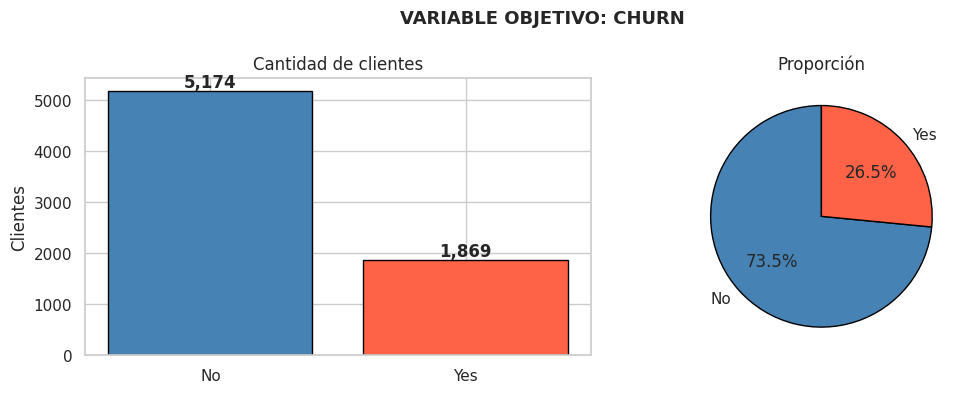

Análisis:
La tasa de abandono es 26.54% (1,869 de 7,043 clientes).
Por cada cliente que abandona hay 2.77 que se quedan: el problema está desbalanceado.
Un clasificador que siempre predijera "No" tendría una accuracy de 73.46% sin detectar a ningún cliente en riesgo,
por eso se evaluará con recall, F1 y ROC-AUC y se usarán pesos de clase.


In [9]:
# Distribución de la variable objetivo
conteo = df['Churn'].value_counts()
porcentaje = df['Churn'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('VARIABLE OBJETIVO: CHURN', fontsize=13, fontweight='bold')

orden = ['No', 'Yes']
axes[0].bar(orden, [conteo[o] for o in orden], color=['steelblue', 'tomato'], edgecolor='black')
for i, o in enumerate(orden):
    axes[0].text(i, conteo[o], f'{conteo[o]:,}', ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Cantidad de clientes')
axes[0].set_ylabel('Clientes')

axes[1].pie([conteo[o] for o in orden], labels=orden, autopct='%1.1f%%',
            colors=['steelblue', 'tomato'], startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1].set_title('Proporción')

plt.tight_layout()
plt.show()

tasa_churn = (df['Churn'] == 'Yes').mean() * 100
print('Análisis:')
print(f'La tasa de abandono es {tasa_churn:.2f}% ({conteo["Yes"]:,} de {len(df):,} clientes).')
print(f'Por cada cliente que abandona hay {conteo["No"] / conteo["Yes"]:.2f} que se quedan: el problema está desbalanceado.')
print(f'Un clasificador que siempre predijera "No" tendría una accuracy de {100 - tasa_churn:.2f}% sin detectar a ningún cliente en riesgo,')
print('por eso se evaluará con recall, F1 y ROC-AUC y se usarán pesos de clase.')

### 2.5 Análisis univariado: variables numéricas
Para la exploración se convierte `TotalCharges` a número (las celdas vacías pasan a `NaN`). El tratamiento definitivo se hace en la Fase 3.

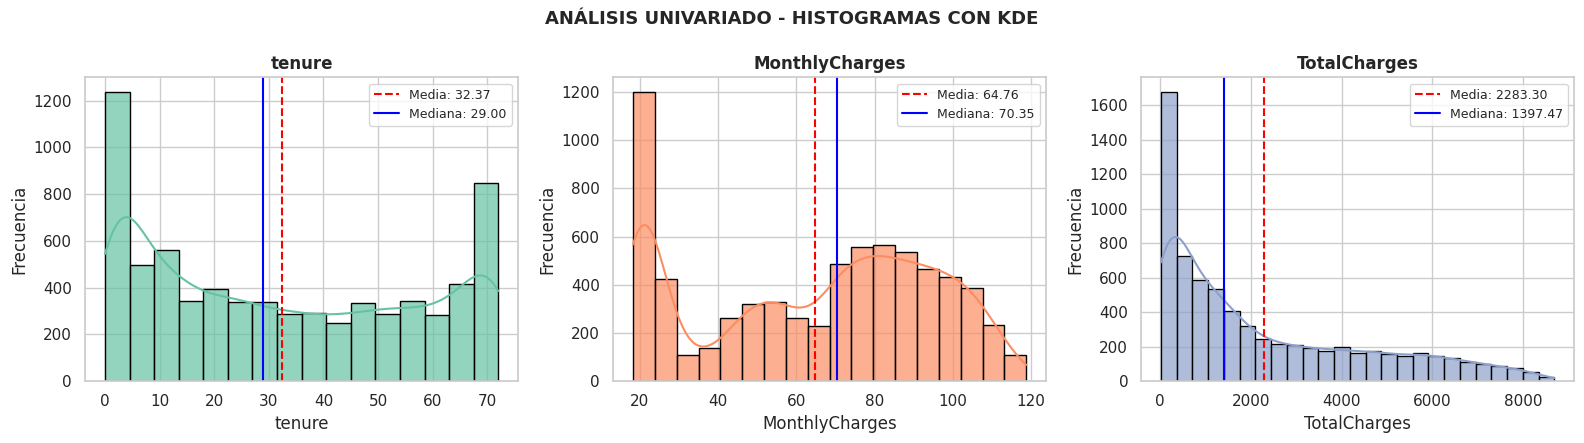

Análisis:
- tenure: media 32.37, mediana 29.00, distribución aproximadamente simétrica (skewness 0.24).
- MonthlyCharges: media 64.76, mediana 70.35, distribución aproximadamente simétrica (skewness -0.22).
- TotalCharges: media 2283.30, mediana 1397.47, distribución con sesgo positivo, cola a la derecha (skewness 0.96).
- El 21.0% de los clientes tiene 6 meses o menos de antigüedad y el 21.1% tiene 60 meses o más.
  Hay concentración en los dos extremos de antigüedad: clientes recién llegados y clientes muy fieles.


In [10]:
# Copia de trabajo para el EDA
df_eda = df.copy()
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'], errors='coerce')
df_eda['ChurnBin'] = (df_eda['Churn'] == 'Yes').astype(int)
vars_num = ['tenure', 'MonthlyCharges', 'TotalCharges']

def describir_forma(serie):
    """Describe la forma de la distribución según su asimetría (skewness)."""
    sk = serie.skew()
    if abs(sk) < 0.5:
        return f'aproximadamente simétrica (skewness {sk:.2f})'
    if sk > 0:
        return f'con sesgo positivo, cola a la derecha (skewness {sk:.2f})'
    return f'con sesgo negativo, cola a la izquierda (skewness {sk:.2f})'

# Histogramas con KDE
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle('ANÁLISIS UNIVARIADO - HISTOGRAMAS CON KDE', fontsize=13, fontweight='bold')
for idx, (variable, ax) in enumerate(zip(vars_num, axes)):
    serie = df_eda[variable].dropna()
    sns.histplot(serie, kde=True, ax=ax, color=plt.cm.Set2(idx), edgecolor='black', alpha=0.7)
    ax.axvline(serie.mean(), color='red', linestyle='--', label=f'Media: {serie.mean():.2f}')
    ax.axvline(serie.median(), color='blue', linestyle='-', label=f'Mediana: {serie.median():.2f}')
    ax.set_title(variable, fontweight='bold')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print('Análisis:')
for variable in vars_num:
    serie = df_eda[variable].dropna()
    print(f'- {variable}: media {serie.mean():.2f}, mediana {serie.median():.2f}, distribución {describir_forma(serie)}.')

nuevos = (df_eda['tenure'] <= 6).mean() * 100
antiguos = (df_eda['tenure'] >= 60).mean() * 100
print(f'- El {nuevos:.1f}% de los clientes tiene 6 meses o menos de antigüedad y el {antiguos:.1f}% tiene 60 meses o más.')
if nuevos > 10 and antiguos > 10:
    print('  Hay concentración en los dos extremos de antigüedad: clientes recién llegados y clientes muy fieles.')

In [11]:
# Detección de valores atípicos con la regla de Tukey (IQR)
def outliers_iqr(serie, factor=1.5):
    serie = serie.dropna()
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    li, ls = q1 - factor * iqr, q3 + factor * iqr
    mask = (serie < li) | (serie > ls)
    return int(mask.sum()), li, ls

filas = []
for variable in vars_num:
    n_out, li, ls = outliers_iqr(df_eda[variable])
    filas.append({'Variable': variable, 'Límite inferior': li, 'Límite superior': ls,
                  'Outliers': n_out, '% del total': n_out / df_eda[variable].notna().sum() * 100})
tabla_outliers = pd.DataFrame(filas).set_index('Variable')
print('DETECCIÓN DE OUTLIERS - MÉTODO IQR')
print('=' * 80)
print(tabla_outliers)

print('\nAnálisis:')
con_out = tabla_outliers[tabla_outliers['Outliers'] > 0]
if con_out.empty:
    print('Ninguna variable numérica presenta valores fuera de los límites de Tukey: no se requiere tratamiento de outliers.')
else:
    for var, fila in con_out.iterrows():
        print(f'- {var}: {int(fila["Outliers"])} valores atípicos ({fila["% del total"]:.2f}%).')
    print('Se evalúa si son errores o clientes legítimos con consumos altos antes de decidir su tratamiento.')

DETECCIÓN DE OUTLIERS - MÉTODO IQR
                Límite inferior  Límite superior  Outliers  % del total
Variable                                                               
tenure                 -60.0000         124.0000         0       0.0000
MonthlyCharges         -46.0250         171.3750         0       0.0000
TotalCharges        -4,688.4813       8,884.6688         0       0.0000

Análisis:
Ninguna variable numérica presenta valores fuera de los límites de Tukey: no se requiere tratamiento de outliers.


### 2.6 Análisis bivariado: variables categóricas frente al abandono

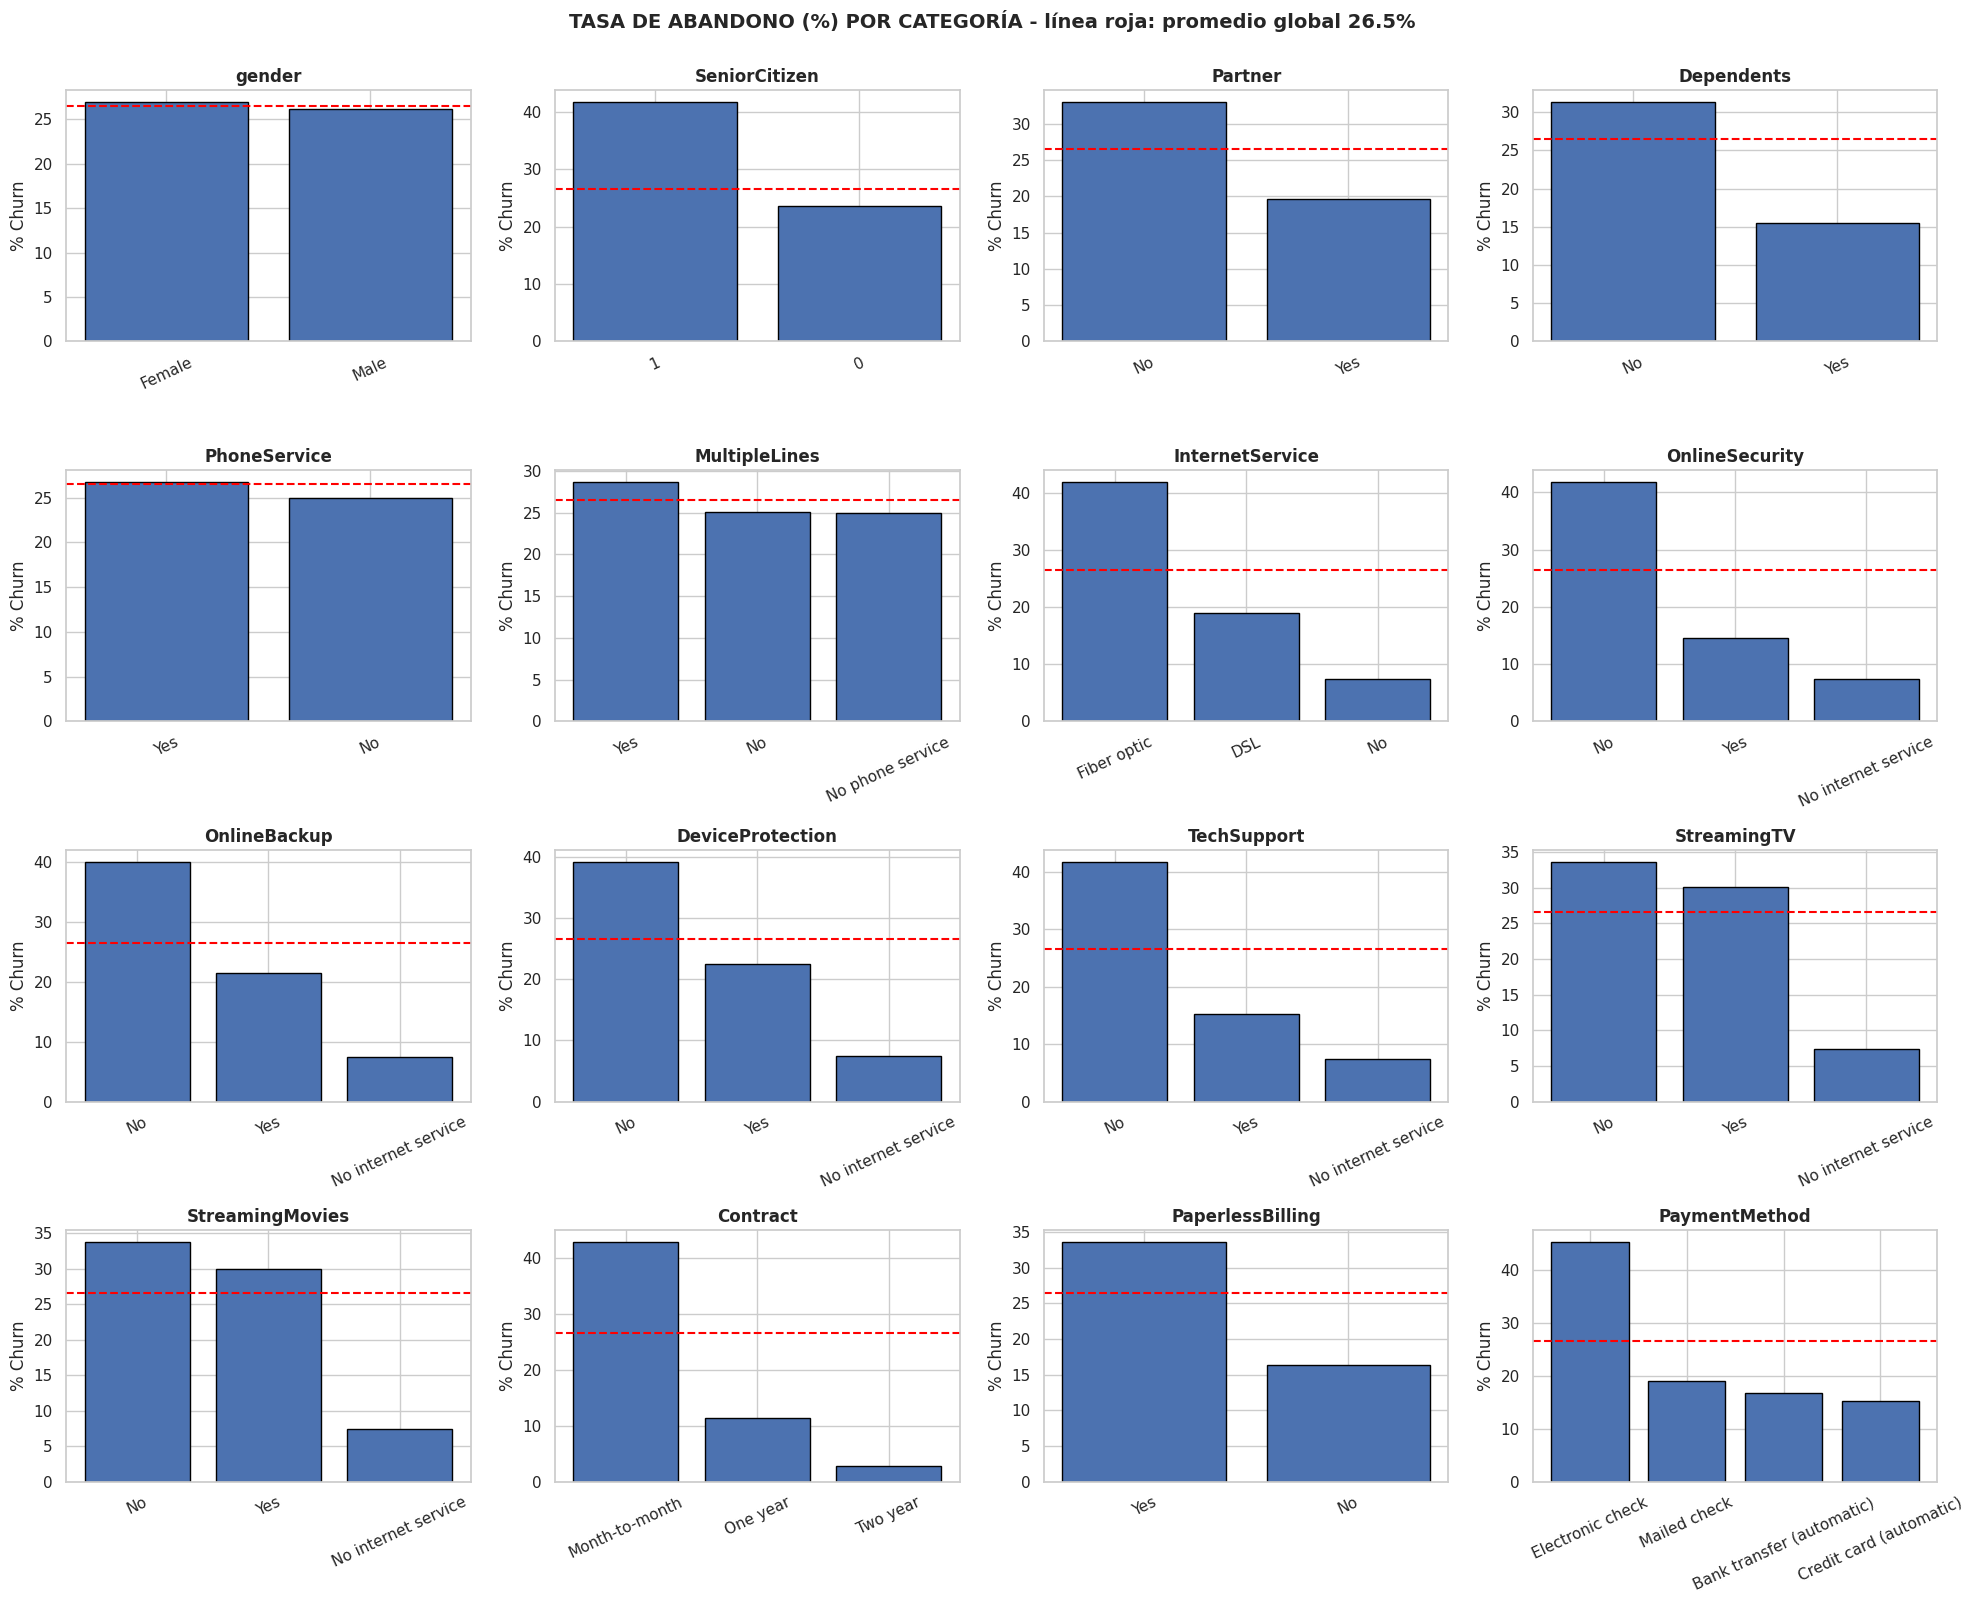

In [12]:
# Tasa de abandono por categoría para cada variable categórica
vars_excluir = ['customerID', 'Churn', 'ChurnBin'] + vars_num
cat_vars = [c for c in df_eda.columns if c not in vars_excluir]
tasa_global = df_eda['ChurnBin'].mean() * 100

n_graf = len(cat_vars)
n_cols_g = 4
n_filas_g = int(np.ceil(n_graf / n_cols_g))
fig, axes = plt.subplots(n_filas_g, n_cols_g, figsize=(20, 4 * n_filas_g))
fig.suptitle(f'TASA DE ABANDONO (%) POR CATEGORÍA - línea roja: promedio global {tasa_global:.1f}%',
             fontsize=14, fontweight='bold', y=1.0)

for ax, var in zip(axes.flatten(), cat_vars):
    tasa = (df_eda.groupby(var)['ChurnBin'].mean() * 100).sort_values(ascending=False)
    ax.bar(tasa.index.astype(str), tasa.values, color=sns.color_palette('deep')[0], edgecolor='black')
    ax.axhline(tasa_global, color='red', linestyle='--')
    ax.set_title(var, fontweight='bold')
    ax.set_ylabel('% Churn')
    ax.tick_params(axis='x', rotation=25)
for ax in axes.flatten()[n_graf:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [13]:
# Asociación estadística de cada variable categórica con Churn (chi-cuadrado y V de Cramér)
filas = []
for var in cat_vars:
    tabla = pd.crosstab(df_eda[var], df_eda['ChurnBin'])
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    n = tabla.values.sum()
    v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    filas.append({'Variable': var, 'Chi2': chi2, 'p-valor': p, 'V de Cramér': v_cramer})
asociacion = pd.DataFrame(filas).sort_values('V de Cramér', ascending=False).set_index('Variable')
print('ASOCIACIÓN CON CHURN (variables categóricas)')
print('=' * 80)
print(asociacion)

# Categorías con mayor y menor tasa de abandono (mínimo 100 clientes)
registros = []
for var in cat_vars:
    g = df_eda.groupby(var)['ChurnBin'].agg(['mean', 'count'])
    for categoria, fila in g.iterrows():
        registros.append({'Variable': var, 'Categoría': str(categoria),
                          'Tasa Churn (%)': fila['mean'] * 100, 'Clientes': int(fila['count'])})
ranking = pd.DataFrame(registros)
ranking = ranking[ranking['Clientes'] >= 100]

print('\nCATEGORÍAS CON MAYOR TASA DE ABANDONO')
print(ranking.sort_values('Tasa Churn (%)', ascending=False).head(5).to_string(index=False))
print('\nCATEGORÍAS CON MENOR TASA DE ABANDONO')
print(ranking.sort_values('Tasa Churn (%)').head(5).to_string(index=False))

print('\nAnálisis:')
top3 = asociacion.head(3).index.tolist()
print(f'Las variables categóricas más asociadas al abandono (mayor V de Cramér) son: {", ".join(top3)}.')
no_signif = asociacion[asociacion['p-valor'] > 0.05].index.tolist()
if no_signif:
    print(f'Sin asociación estadísticamente significativa (p > 0.05): {", ".join(no_signif)}.')
else:
    print('Todas las variables categóricas muestran asociación significativa con Churn (p <= 0.05).')
mayor = ranking.sort_values('Tasa Churn (%)', ascending=False).iloc[0]
print(f'La categoría de mayor riesgo es {mayor["Variable"]} = {mayor["Categoría"]}, con {mayor["Tasa Churn (%)"]:.1f}% de abandono frente al {tasa_global:.1f}% global.')

ASOCIACIÓN CON CHURN (variables categóricas)
                       Chi2  p-valor  V de Cramér
Variable                                         
Contract         1,184.5966   0.0000       0.4101
OnlineSecurity     849.9990   0.0000       0.3474
TechSupport        828.1971   0.0000       0.3429
InternetService    732.3096   0.0000       0.3225
PaymentMethod      648.1423   0.0000       0.3034
OnlineBackup       601.8128   0.0000       0.2923
DeviceProtection   558.4194   0.0000       0.2816
StreamingMovies    375.6615   0.0000       0.2310
StreamingTV        374.2039   0.0000       0.2305
PaperlessBilling   258.2776   0.0000       0.1915
Dependents         189.1292   0.0000       0.1639
SeniorCitizen      159.4263   0.0000       0.1505
Partner            158.7334   0.0000       0.1501
MultipleLines       11.3304   0.0035       0.0401
PhoneService         0.9150   0.3388       0.0114
gender               0.4841   0.4866       0.0083

CATEGORÍAS CON MAYOR TASA DE ABANDONO
       Variable 

### 2.7 Análisis bivariado: variables numéricas frente al abandono

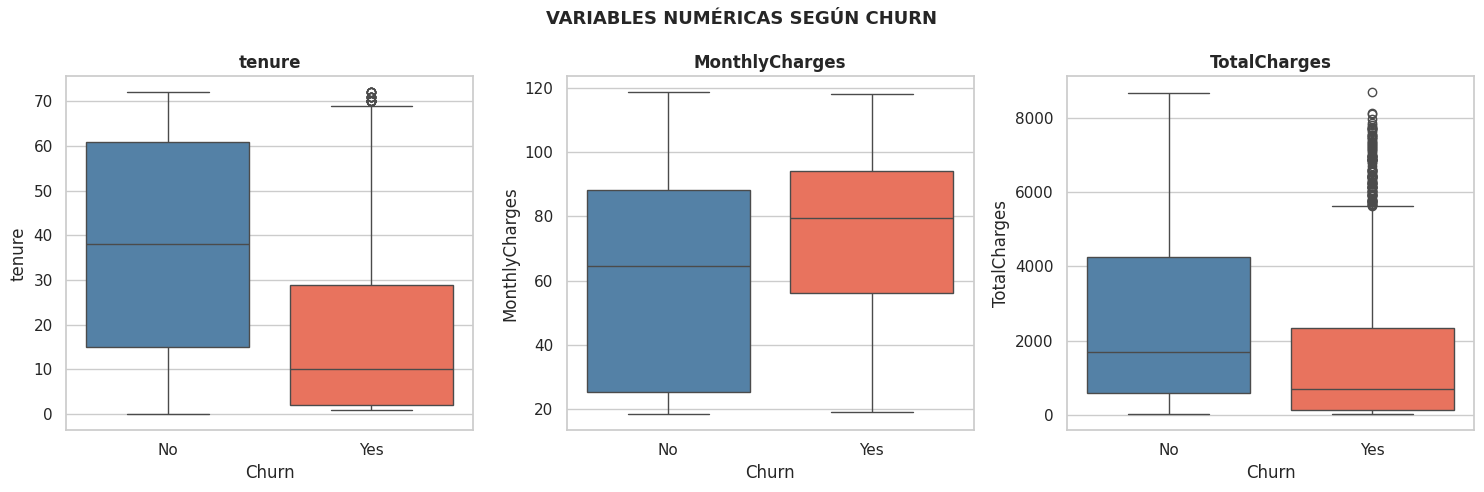

                Mediana (No)  Mediana (Yes)  p-valor Mann-Whitney
Variable                                                         
tenure               38.0000        10.0000                0.0000
MonthlyCharges       64.4250        79.6500                0.0000
TotalCharges      1,683.6000       703.5500                0.0000

Análisis:
- tenure: los clientes que abandonan tienen una mediana menor (10.00 vs 38.00); diferencia significativa.
- MonthlyCharges: los clientes que abandonan tienen una mediana mayor (79.65 vs 64.43); diferencia significativa.
- TotalCharges: los clientes que abandonan tienen una mediana menor (703.55 vs 1683.60); diferencia significativa.


In [14]:
# Comparación de variables numéricas entre quienes abandonan y quienes se quedan
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('VARIABLES NUMÉRICAS SEGÚN CHURN', fontsize=13, fontweight='bold')
for ax, variable in zip(axes, vars_num):
    sns.boxplot(data=df_eda, x='Churn', y=variable, order=['No', 'Yes'], ax=ax,
                palette=['steelblue', 'tomato'])
    ax.set_title(variable, fontweight='bold')
plt.tight_layout()
plt.show()

filas = []
for variable in vars_num:
    g_no = df_eda.loc[df_eda['Churn'] == 'No', variable].dropna()
    g_si = df_eda.loc[df_eda['Churn'] == 'Yes', variable].dropna()
    u, p = stats.mannwhitneyu(g_no, g_si, alternative='two-sided')
    filas.append({'Variable': variable, 'Mediana (No)': g_no.median(), 'Mediana (Yes)': g_si.median(),
                  'p-valor Mann-Whitney': p})
comparacion = pd.DataFrame(filas).set_index('Variable')
print(comparacion)

print('\nAnálisis:')
for var, fila in comparacion.iterrows():
    sentido = 'mayor' if fila['Mediana (Yes)'] > fila['Mediana (No)'] else 'menor'
    signif = 'diferencia significativa' if fila['p-valor Mann-Whitney'] < 0.05 else 'sin diferencia significativa'
    print(f'- {var}: los clientes que abandonan tienen una mediana {sentido} ({fila["Mediana (Yes)"]:.2f} vs {fila["Mediana (No)"]:.2f}); {signif}.')

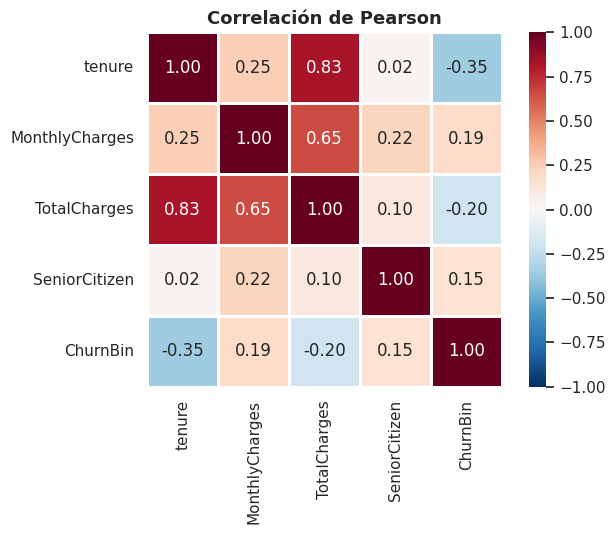

Análisis:
- Correlación tenure - Churn: -0.35 (a mayor antigüedad, menor abandono).
- Correlación MonthlyCharges - Churn: 0.19.
- Correlación tenure - TotalCharges: 0.83: el cargo acumulado crece con la antigüedad, por lo que ambas variables aportan información parecida.


In [15]:
# Matriz de correlación de Pearson
cols_corr = vars_num + ['SeniorCitizen', 'ChurnBin']
corr = df_eda[cols_corr].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=1)
plt.title('Correlación de Pearson', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Análisis:')
print(f'- Correlación tenure - Churn: {corr.loc["tenure", "ChurnBin"]:.2f} (a mayor antigüedad, {"menor" if corr.loc["tenure", "ChurnBin"] < 0 else "mayor"} abandono).')
print(f'- Correlación MonthlyCharges - Churn: {corr.loc["MonthlyCharges", "ChurnBin"]:.2f}.')
print(f'- Correlación tenure - TotalCharges: {corr.loc["tenure", "TotalCharges"]:.2f}: el cargo acumulado crece con la antigüedad, por lo que ambas variables aportan información parecida.')

### 2.8 Análisis multivariado

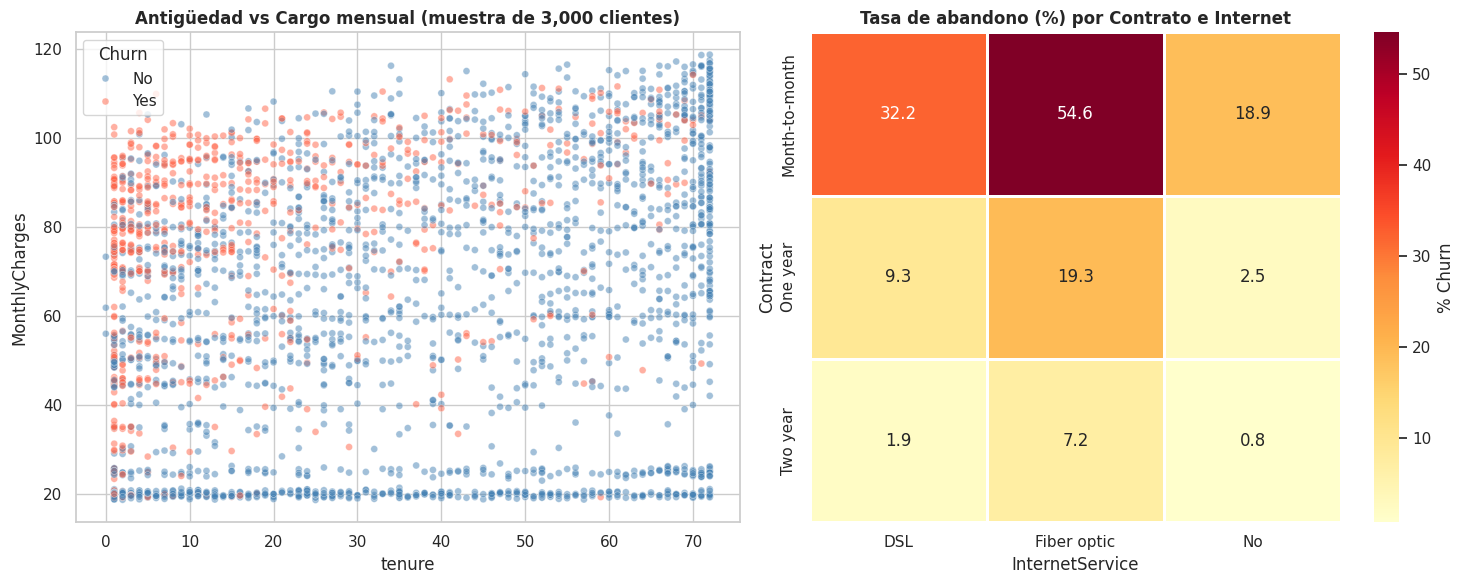

Análisis:
- La combinación con mayor abandono es Contract = Month-to-month con InternetService = Fiber optic (54.6%).
- La de menor abandono es Contract = Two year con InternetService = No (0.8%).
- El riesgo depende de la combinación de variables, no de una sola: es una razón para usar modelos que capturen interacciones.


In [16]:
# Relación tenure - MonthlyCharges coloreada por Churn, y tasa de abandono por Contract x InternetService
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

muestra = df_eda.sample(n=min(3000, len(df_eda)), random_state=SEED)
sns.scatterplot(data=muestra, x='tenure', y='MonthlyCharges', hue='Churn', hue_order=['No', 'Yes'],
                palette=['steelblue', 'tomato'], alpha=0.5, s=25, ax=axes[0])
axes[0].set_title('Antigüedad vs Cargo mensual (muestra de 3,000 clientes)', fontweight='bold')

pivote = df_eda.pivot_table(index='Contract', columns='InternetService', values='ChurnBin', aggfunc='mean') * 100
sns.heatmap(pivote, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=1, ax=axes[1], cbar_kws={'label': '% Churn'})
axes[1].set_title('Tasa de abandono (%) por Contrato e Internet', fontweight='bold')

plt.tight_layout()
plt.show()

print('Análisis:')
celda_max = pivote.stack().idxmax()
celda_min = pivote.stack().idxmin()
print(f'- La combinación con mayor abandono es Contract = {celda_max[0]} con InternetService = {celda_max[1]} ({pivote.stack().max():.1f}%).')
print(f'- La de menor abandono es Contract = {celda_min[0]} con InternetService = {celda_min[1]} ({pivote.stack().min():.1f}%).')
print('- El riesgo depende de la combinación de variables, no de una sola: es una razón para usar modelos que capturen interacciones.')

## Fase 3. Preprocesamiento

Se limpian los datos, se transforman las variables y se generan variables nuevas. Todo lo que *aprende* de los datos (escalado, codificación) se ajusta solo con el conjunto de entrenamiento y dentro de un `Pipeline`, para evitar fuga de información (*data leakage*).

### 3.1 Limpieza

In [17]:
# 3.1 LIMPIEZA
df_limpio = df.copy()

# El identificador no aporta poder predictivo
df_limpio = df_limpio.drop(columns=['customerID'])

# TotalCharges: de texto a número
df_limpio['TotalCharges'] = pd.to_numeric(df_limpio['TotalCharges'], errors='coerce')
mask_na = df_limpio['TotalCharges'].isna()
print(f'Valores de TotalCharges convertidos a NaN por estar vacíos: {int(mask_na.sum())}')

if mask_na.sum() > 0 and (df_limpio.loc[mask_na, 'tenure'] == 0).all():
    df_limpio.loc[mask_na, 'TotalCharges'] = 0.0
    print('Todos tienen tenure = 0 (clientes sin facturación acumulada): se imputa TotalCharges = 0.')
elif mask_na.sum() > 0:
    mediana = df_limpio['TotalCharges'].median()
    df_limpio['TotalCharges'] = df_limpio['TotalCharges'].fillna(mediana)
    print(f'No todos tienen tenure = 0: se imputa con la mediana ({mediana:.2f}).')

# Unificar etiquetas redundantes: "No internet service" y "No phone service" equivalen a "No"
cols_servicio = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']
for c in cols_servicio:
    df_limpio[c] = df_limpio[c].replace({'No internet service': 'No', 'No phone service': 'No'})

# SeniorCitizen es categórica: se pasa de 0/1 a No/Yes
df_limpio['SeniorCitizen'] = df_limpio['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# Variable objetivo en formato numérico: 1 = abandona, 0 = se queda
df_limpio['Churn'] = (df_limpio['Churn'] == 'Yes').astype(int)

print(f'\nNulos restantes: {int(df_limpio.isnull().sum().sum())}')
print(f'Dimensiones tras la limpieza: {df_limpio.shape[0]:,} x {df_limpio.shape[1]}')
print('\nAnálisis:')
print('Se eliminó el identificador, se corrigió el tipo de TotalCharges y se unificaron las categorías redundantes de servicios.')
print('El dataset queda sin valores nulos y con la variable objetivo codificada como 0/1.')

Valores de TotalCharges convertidos a NaN por estar vacíos: 11
Todos tienen tenure = 0 (clientes sin facturación acumulada): se imputa TotalCharges = 0.

Nulos restantes: 0
Dimensiones tras la limpieza: 7,043 x 20

Análisis:
Se eliminó el identificador, se corrigió el tipo de TotalCharges y se unificaron las categorías redundantes de servicios.
El dataset queda sin valores nulos y con la variable objetivo codificada como 0/1.


### 3.2 Generación de variables (*feature engineering*)
Se crean variables que resumen el comportamiento del cliente:

- `n_servicios`: cantidad de servicios contratados.
- `gasto_medio_mensual`: cargo acumulado dividido por los meses de antigüedad.
- `variacion_cargo`: diferencia entre el cargo mensual actual y el gasto medio histórico (señal de aumentos de precio).
- `tenure_grupo`: antigüedad agrupada en tramos.
- `tiene_proteccion`: si el cliente tiene al menos un servicio de seguridad, respaldo, protección de equipo o soporte técnico.

Variables nuevas: ['n_servicios', 'gasto_medio_mensual', 'variacion_cargo', 'tenure_grupo', 'tiene_proteccion']


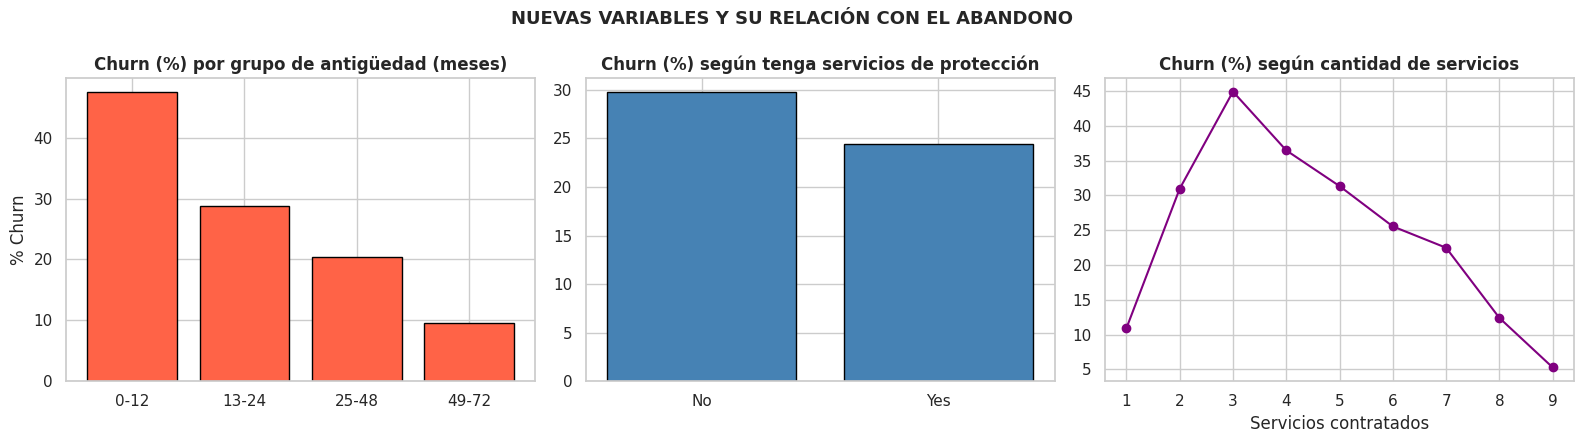

Análisis:
- Churn en clientes con 0-12 meses: 47.4%; con 49-72 meses: 9.5%.
- Churn con servicios de protección: 24.4%; sin ellos: 29.8%.
- Correlación de las nuevas variables numéricas con Churn: n_servicios -0.02, gasto_medio_mensual 0.19, variacion_cargo -0.01.


In [18]:
# 3.2 FEATURE ENGINEERING
df_fe = df_limpio.copy()

servicios = ['PhoneService'] + cols_servicio
df_fe['n_servicios'] = (df_fe[servicios] == 'Yes').sum(axis=1) + (df_fe['InternetService'] != 'No').astype(int)

df_fe['gasto_medio_mensual'] = df_fe['TotalCharges'] / df_fe['tenure'].clip(lower=1)
df_fe['variacion_cargo'] = df_fe['MonthlyCharges'] - df_fe['gasto_medio_mensual']

df_fe['tenure_grupo'] = pd.cut(df_fe['tenure'], bins=[-1, 12, 24, 48, 72],
                               labels=['0-12', '13-24', '25-48', '49-72']).astype(str)

proteccion = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
df_fe['tiene_proteccion'] = np.where((df_fe[proteccion] == 'Yes').any(axis=1), 'Yes', 'No')

print('Variables nuevas:', ['n_servicios', 'gasto_medio_mensual', 'variacion_cargo', 'tenure_grupo', 'tiene_proteccion'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle('NUEVAS VARIABLES Y SU RELACIÓN CON EL ABANDONO', fontsize=13, fontweight='bold')

orden_t = ['0-12', '13-24', '25-48', '49-72']
tasa_t = df_fe.groupby('tenure_grupo')['Churn'].mean().reindex(orden_t) * 100
axes[0].bar(orden_t, tasa_t.values, color='tomato', edgecolor='black')
axes[0].set_title('Churn (%) por grupo de antigüedad (meses)', fontweight='bold')
axes[0].set_ylabel('% Churn')

tasa_p = df_fe.groupby('tiene_proteccion')['Churn'].mean() * 100
axes[1].bar(tasa_p.index, tasa_p.values, color='steelblue', edgecolor='black')
axes[1].set_title('Churn (%) según tenga servicios de protección', fontweight='bold')

tasa_n = df_fe.groupby('n_servicios')['Churn'].mean() * 100
axes[2].plot(tasa_n.index, tasa_n.values, marker='o', color='purple')
axes[2].set_title('Churn (%) según cantidad de servicios', fontweight='bold')
axes[2].set_xlabel('Servicios contratados')

plt.tight_layout()
plt.show()

print('Análisis:')
print(f'- Churn en clientes con 0-12 meses: {tasa_t["0-12"]:.1f}%; con 49-72 meses: {tasa_t["49-72"]:.1f}%.')
print(f'- Churn con servicios de protección: {tasa_p["Yes"]:.1f}%; sin ellos: {tasa_p["No"]:.1f}%.')
print(f'- Correlación de las nuevas variables numéricas con Churn: '
      f'n_servicios {df_fe["n_servicios"].corr(df_fe["Churn"]):.2f}, '
      f'gasto_medio_mensual {df_fe["gasto_medio_mensual"].corr(df_fe["Churn"]):.2f}, '
      f'variacion_cargo {df_fe["variacion_cargo"].corr(df_fe["Churn"]):.2f}.')

### 3.3 División en entrenamiento y prueba, codificación y escalado
Se separa el 20% de los datos como conjunto de prueba (estratificado para conservar la proporción de *Churn*). El conjunto de prueba **no se toca** hasta la evaluación final.

In [19]:
# 3.3 DIVISIÓN TRAIN / TEST
X = df_fe.drop(columns=['Churn'])
y = df_fe['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f'Entrenamiento: {X_train.shape[0]:,} registros | Prueba: {X_test.shape[0]:,} registros')
print(f'Tasa de Churn en entrenamiento: {y_train.mean() * 100:.2f}% | en prueba: {y_test.mean() * 100:.2f}%')

# Columnas numéricas y categóricas
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_servicios', 'gasto_medio_mensual', 'variacion_cargo']
cat_cols = [c for c in X.columns if c not in num_cols]

# Preprocesador: escalado de numéricas + one-hot de categóricas
preprocesador = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

# Demostración sobre el entrenamiento (en el modelado se ajusta dentro de cada Pipeline)
Xt = preprocesador.fit_transform(X_train)
print(f'\nVariables numéricas: {len(num_cols)} | categóricas: {len(cat_cols)}')
print(f'Matriz transformada de entrenamiento: {Xt.shape[0]:,} filas x {Xt.shape[1]} columnas')

print('\nAnálisis:')
print('La división estratificada mantiene la misma tasa de abandono en ambos conjuntos.')
print(f'Tras el one-hot, las {X.shape[1]} variables originales pasan a {Xt.shape[1]} columnas numéricas.')
print('El desbalance de clases se tratará con pesos de clase (class_weight="balanced") en los modelos que lo admiten.')

Entrenamiento: 5,634 registros | Prueba: 1,409 registros
Tasa de Churn en entrenamiento: 26.54% | en prueba: 26.54%

Variables numéricas: 6 | categóricas: 18
Matriz transformada de entrenamiento: 5,634 filas x 48 columnas

Análisis:
La división estratificada mantiene la misma tasa de abandono en ambos conjuntos.
Tras el one-hot, las 24 variables originales pasan a 48 columnas numéricas.
El desbalance de clases se tratará con pesos de clase (class_weight="balanced") en los modelos que lo admiten.


## Fase 4. Modelado

### 4.1 Modelo descriptivo: segmentación de clientes con K-Means
El clustering es una técnica **no supervisada**: agrupa clientes parecidos sin usar la variable `Churn`. Después se perfila cada grupo y se comprueba si los segmentos difieren en su tasa de abandono.

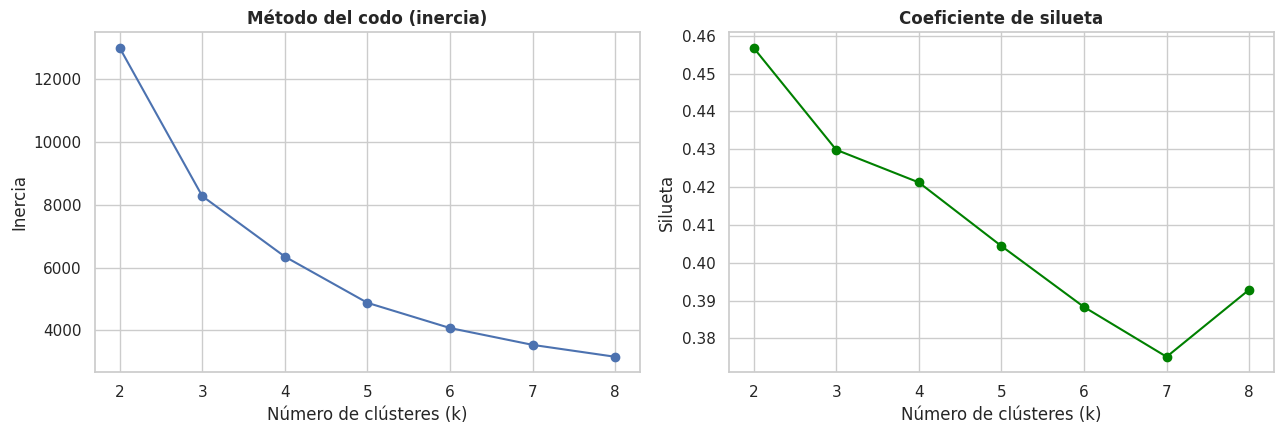

Análisis:
El mayor coeficiente de silueta (0.457) se obtiene con k = 2.
Se trabaja con k = 2. Una silueta cercana a 0.5 indica grupos bien separados; valores bajos indican grupos que se solapan.


In [20]:
# 4.1 K-MEANS: selección de k con el método del codo y el coeficiente de silueta
vars_cluster = ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_servicios']
Z = StandardScaler().fit_transform(df_fe[vars_cluster])

rango_k = list(range(2, 9))
inercias, siluetas = [], []
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(rango_k, inercias, marker='o')
axes[0].set_title('Método del codo (inercia)', fontweight='bold')
axes[0].set_xlabel('Número de clústeres (k)')
axes[0].set_ylabel('Inercia')
axes[1].plot(rango_k, siluetas, marker='o', color='green')
axes[1].set_title('Coeficiente de silueta', fontweight='bold')
axes[1].set_xlabel('Número de clústeres (k)')
axes[1].set_ylabel('Silueta')
plt.tight_layout()
plt.show()

k_opt = rango_k[int(np.argmax(siluetas))]
K_ELEGIDO = k_opt   # puedes cambiarlo (por ejemplo a 3 o 4) si buscas segmentos más detallados
print('Análisis:')
print(f'El mayor coeficiente de silueta ({max(siluetas):.3f}) se obtiene con k = {k_opt}.')
print(f'Se trabaja con k = {K_ELEGIDO}. Una silueta cercana a 0.5 indica grupos bien separados; valores bajos indican grupos que se solapan.')

PERFIL DE LOS CLÚSTERES
         clientes  tenure_medio  cargo_mensual_medio  cargo_total_medio  \
cluster                                                                   
0            2577       54.0081              89.8009         4,829.7573   
1            4466       19.8860              50.3134           808.3037   

         servicios_medios  tasa_churn  
cluster                                
0                  6.4633     18.1218  
1                  2.8092     31.3927  


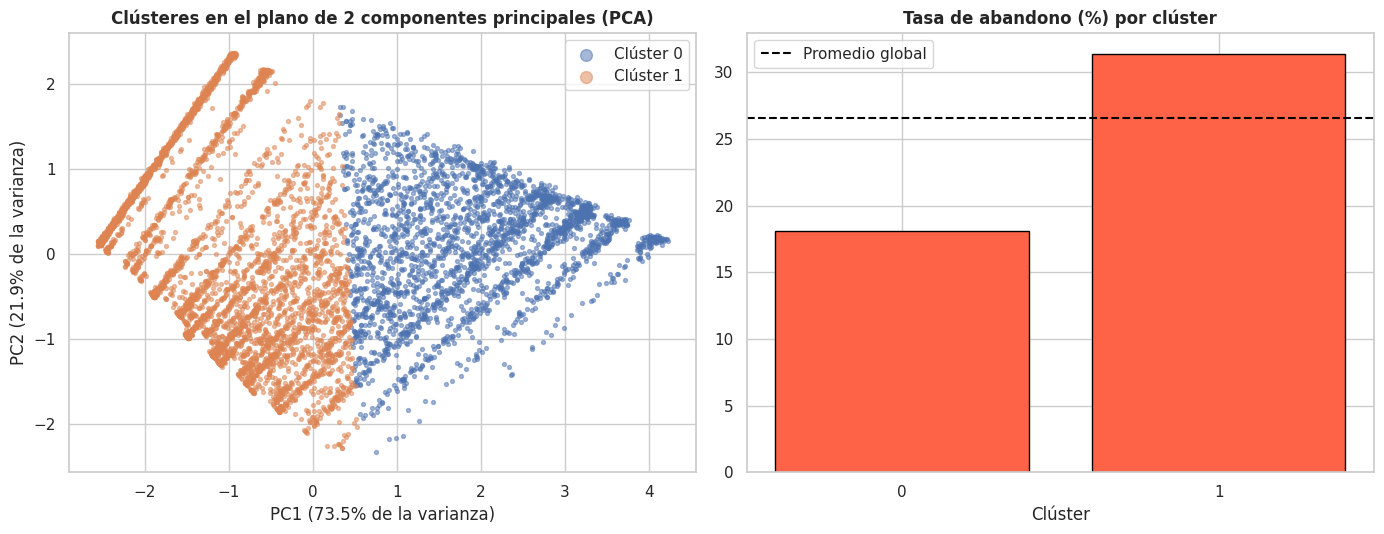

Análisis:
- El clúster 1 tiene la mayor tasa de abandono (31.4%), con una antigüedad media de 19.9 meses, un cargo mensual medio de 50.31 y 2.8 servicios.
- El clúster 0 tiene la menor (18.1%), con 54.0 meses de antigüedad y 6.5 servicios.
- Aunque el clustering no usó Churn, los segmentos muestran riesgos distintos: sirven para diseñar campañas de retención diferenciadas.


In [21]:
# 4.1 PERFIL DE LOS CLÚSTERES
km_final = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEED).fit(Z)
df_seg = df_fe.copy()
df_seg['cluster'] = km_final.labels_

perfil = df_seg.groupby('cluster').agg(
    clientes=('Churn', 'size'),
    tenure_medio=('tenure', 'mean'),
    cargo_mensual_medio=('MonthlyCharges', 'mean'),
    cargo_total_medio=('TotalCharges', 'mean'),
    servicios_medios=('n_servicios', 'mean'),
    tasa_churn=('Churn', 'mean')
)
perfil['tasa_churn'] = perfil['tasa_churn'] * 100
print('PERFIL DE LOS CLÚSTERES')
print('=' * 80)
print(perfil)

# Proyección a 2 componentes principales para visualizar los grupos
pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for c in range(K_ELEGIDO):
    m = df_seg['cluster'].values == c
    axes[0].scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=0.5, label=f'Clúster {c}')
axes[0].set_title('Clústeres en el plano de 2 componentes principales (PCA)', fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% de la varianza)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% de la varianza)')
axes[0].legend(markerscale=3)

axes[1].bar(perfil.index.astype(str), perfil['tasa_churn'], color='tomato', edgecolor='black')
axes[1].axhline(df_fe['Churn'].mean() * 100, color='black', linestyle='--', label='Promedio global')
axes[1].set_title('Tasa de abandono (%) por clúster', fontweight='bold')
axes[1].set_xlabel('Clúster')
axes[1].legend()
plt.tight_layout()
plt.show()

c_max = perfil['tasa_churn'].idxmax()
c_min = perfil['tasa_churn'].idxmin()
print('Análisis:')
print(f'- El clúster {c_max} tiene la mayor tasa de abandono ({perfil.loc[c_max, "tasa_churn"]:.1f}%), con una antigüedad media de {perfil.loc[c_max, "tenure_medio"]:.1f} meses, un cargo mensual medio de {perfil.loc[c_max, "cargo_mensual_medio"]:.2f} y {perfil.loc[c_max, "servicios_medios"]:.1f} servicios.')
print(f'- El clúster {c_min} tiene la menor ({perfil.loc[c_min, "tasa_churn"]:.1f}%), con {perfil.loc[c_min, "tenure_medio"]:.1f} meses de antigüedad y {perfil.loc[c_min, "servicios_medios"]:.1f} servicios.')
print('- Aunque el clustering no usó Churn, los segmentos muestran riesgos distintos: sirven para diseñar campañas de retención diferenciadas.')

### 4.2 Modelos predictivos: clasificación del abandono
Se comparan cinco algoritmos de naturaleza distinta (lineal, basado en distancias, árbol, *bagging* y *boosting*). Cada uno se envuelve en un `Pipeline` con el preprocesador y se evalúa con **validación cruzada estratificada de 5 pliegues sobre el conjunto de entrenamiento**.

Regresión Logística: F1 = 0.627 | ROC-AUC = 0.846
KNN (k=15): F1 = 0.585 | ROC-AUC = 0.823
Árbol de Decisión: F1 = 0.607 | ROC-AUC = 0.826
Random Forest: F1 = 0.631 | ROC-AUC = 0.846
Gradient Boosting (Hist): F1 = 0.614 | ROC-AUC = 0.834

RESULTADOS DE VALIDACIÓN CRUZADA (media ± desviación estándar, 5 pliegues)
                               accuracy      precision         recall  \
Regresión Logística       0.750 ± 0.013  0.519 ± 0.016  0.794 ± 0.041   
KNN (k=15)                0.790 ± 0.009  0.614 ± 0.019  0.558 ± 0.019   
Árbol de Decisión         0.729 ± 0.007  0.493 ± 0.008  0.791 ± 0.009   
Random Forest             0.781 ± 0.014  0.571 ± 0.022  0.706 ± 0.037   
Gradient Boosting (Hist)  0.766 ± 0.010  0.546 ± 0.014  0.702 ± 0.033   

                                     f1        roc_auc  
Regresión Logística       0.627 ± 0.023  0.846 ± 0.012  
KNN (k=15)                0.585 ± 0.019  0.823 ± 0.008  
Árbol de Decisión         0.607 ± 0.009  0.826 ± 0.008  
Random Forest      

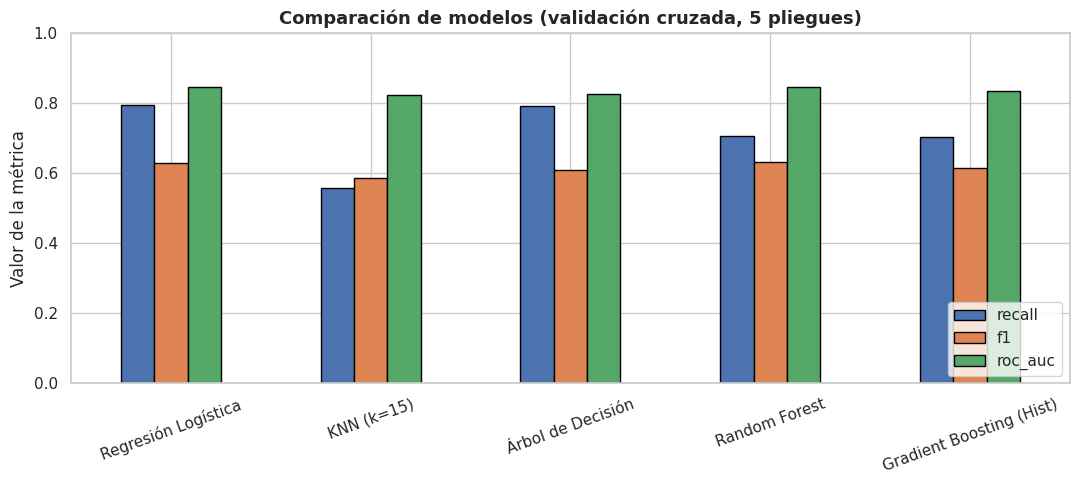

Análisis:
- Mejor F1 en validación cruzada: Random Forest (0.631).
- Mejor ROC-AUC en validación cruzada: Random Forest (0.846).
- Mayor recall (detecta más clientes que se van): Regresión Logística (0.794).
- Si la diferencia entre modelos es menor que la desviación estándar entre pliegues, no se puede afirmar que uno sea mejor que otro.


In [22]:
# 4.2 COMPARACIÓN DE MODELOS CON VALIDACIÓN CRUZADA
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
    'KNN (k=15)': KNeighborsClassifier(n_neighbors=15),
    'Árbol de Decisión': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                            random_state=SEED, n_jobs=-1),
    'Gradient Boosting (Hist)': HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

resultados_cv = {}
for nombre, clf in modelos.items():
    pipe = Pipeline([('prep', preprocesador), ('clf', clf)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas)
    resultados_cv[nombre] = {m: res[f'test_{m}'] for m in metricas}
    print(f'{nombre}: F1 = {res["test_f1"].mean():.3f} | ROC-AUC = {res["test_roc_auc"].mean():.3f}')

medias_cv = pd.DataFrame({n: {m: v.mean() for m, v in d.items()} for n, d in resultados_cv.items()}).T
tabla_cv = pd.DataFrame({n: {m: f'{v.mean():.3f} ± {v.std():.3f}' for m, v in d.items()} for n, d in resultados_cv.items()}).T
print('\nRESULTADOS DE VALIDACIÓN CRUZADA (media ± desviación estándar, 5 pliegues)')
print('=' * 80)
print(tabla_cv)

medias_cv[['recall', 'f1', 'roc_auc']].plot(kind='bar', figsize=(11, 5), edgecolor='black')
plt.title('Comparación de modelos (validación cruzada, 5 pliegues)', fontsize=13, fontweight='bold')
plt.ylabel('Valor de la métrica')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

mejor_f1 = medias_cv['f1'].idxmax()
mejor_auc = medias_cv['roc_auc'].idxmax()
print('Análisis:')
print(f'- Mejor F1 en validación cruzada: {mejor_f1} ({medias_cv.loc[mejor_f1, "f1"]:.3f}).')
print(f'- Mejor ROC-AUC en validación cruzada: {mejor_auc} ({medias_cv.loc[mejor_auc, "roc_auc"]:.3f}).')
print(f'- Mayor recall (detecta más clientes que se van): {medias_cv["recall"].idxmax()} ({medias_cv["recall"].max():.3f}).')
print('- Si la diferencia entre modelos es menor que la desviación estándar entre pliegues, no se puede afirmar que uno sea mejor que otro.')

## Fase 5. Evaluación

### 5.1 Desempeño de los modelos en el conjunto de prueba
Ahora sí se usa el conjunto de prueba, que ningún modelo ha visto. Se entrena cada modelo con todo el entrenamiento y se mide su desempeño.

MÉTRICAS EN EL CONJUNTO DE PRUEBA (umbral 0.5)
                          Accuracy  Precision  Recall     F1  ROC-AUC
Modelo                                                               
Regresión Logística         0.7402     0.5070  0.7781 0.6139   0.8418
KNN (k=15)                  0.7857     0.6040  0.5588 0.5806   0.8171
Árbol de Decisión           0.7537     0.5238  0.7941 0.6312   0.8344
Random Forest               0.7722     0.5542  0.7246 0.6280   0.8431
Gradient Boosting (Hist)    0.7665     0.5440  0.7433 0.6282   0.8344


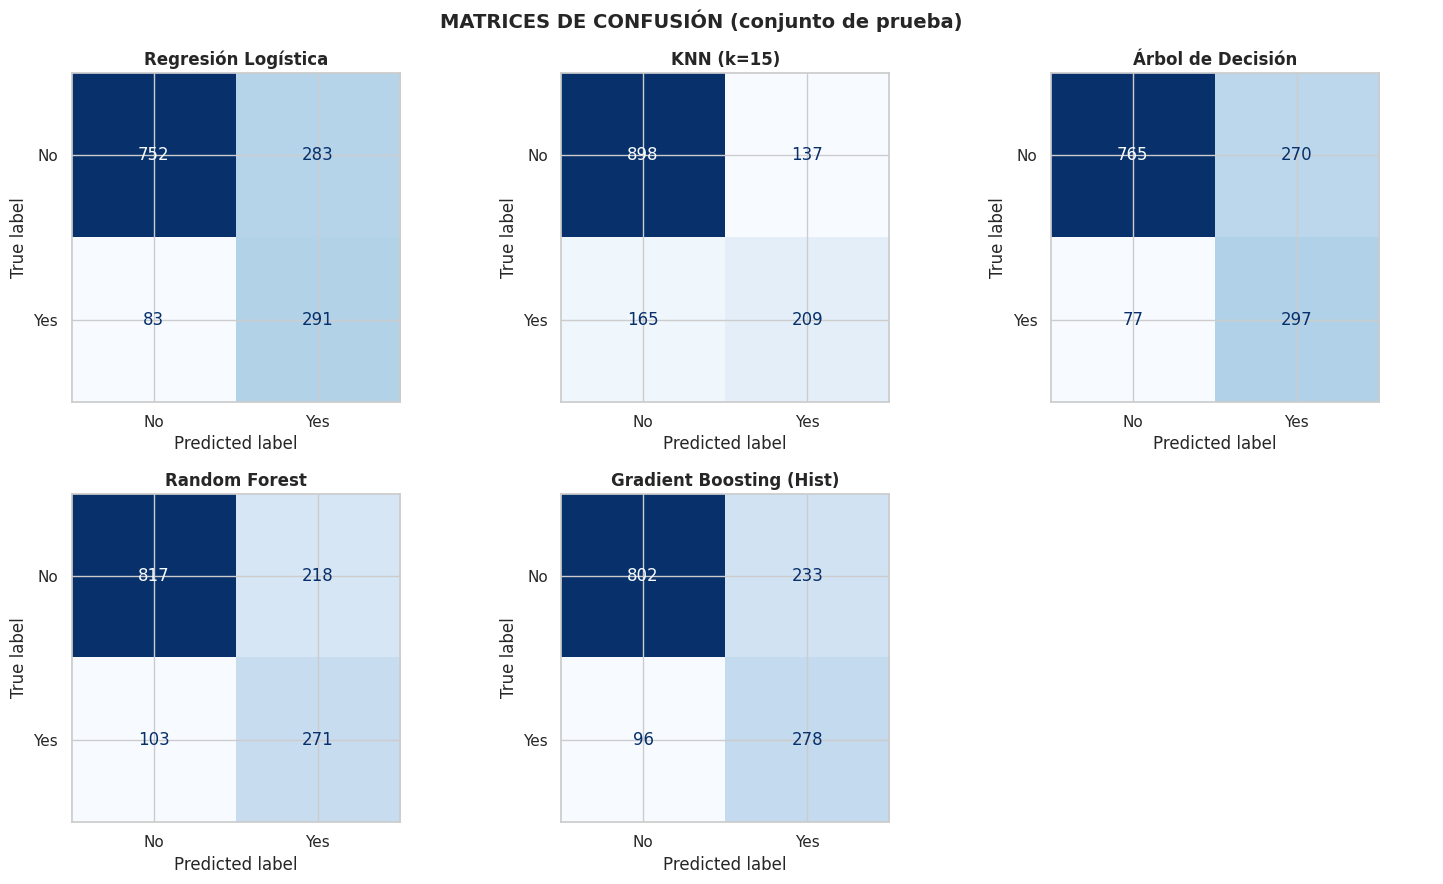

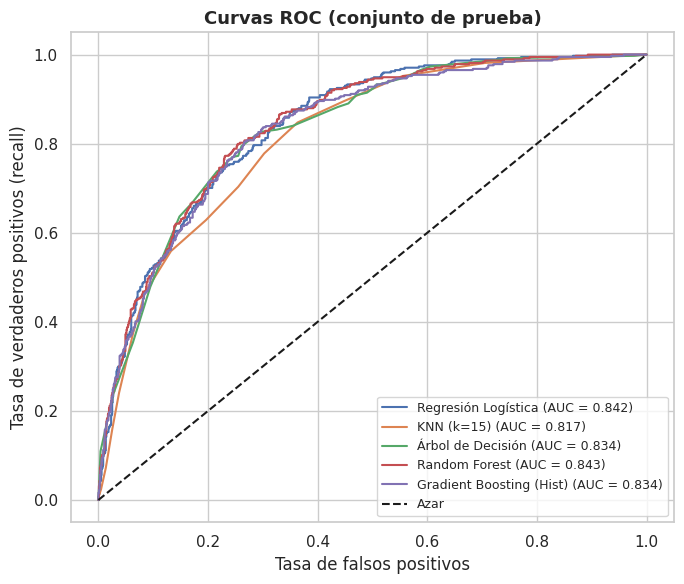

Análisis:
- En prueba, el mejor F1 corresponde a Árbol de Decisión (0.631) y el mejor ROC-AUC a Random Forest (0.843).
- La accuracy más alta (0.786) no coincide necesariamente con el mejor recall (0.794): con clases desbalanceadas conviene mirar ambos.
- En la matriz de confusión, los falsos negativos (abandonos no detectados) son los errores más costosos para el negocio.


In [23]:
# 5.1 EVALUACIÓN EN EL CONJUNTO DE PRUEBA
def calcular_metricas(y_real, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    return {'Accuracy': accuracy_score(y_real, pred),
            'Precision': precision_score(y_real, pred, zero_division=0),
            'Recall': recall_score(y_real, pred),
            'F1': f1_score(y_real, pred),
            'ROC-AUC': roc_auc_score(y_real, proba)}

modelos_ajustados, probas_test, filas = {}, {}, []
for nombre, clf in modelos.items():
    pipe = Pipeline([('prep', preprocesador), ('clf', clf)]).fit(X_train, y_train)
    modelos_ajustados[nombre] = pipe
    probas_test[nombre] = pipe.predict_proba(X_test)[:, 1]
    fila = calcular_metricas(y_test, probas_test[nombre])
    fila['Modelo'] = nombre
    filas.append(fila)

tabla_test = pd.DataFrame(filas).set_index('Modelo')
print('MÉTRICAS EN EL CONJUNTO DE PRUEBA (umbral 0.5)')
print('=' * 80)
print(tabla_test)

# Matrices de confusión
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (nombre, proba) in zip(axes.flatten(), probas_test.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=['No', 'Yes'], cmap='Blues')
    ax.set_title(nombre, fontweight='bold')
for ax in axes.flatten()[len(probas_test):]:
    ax.axis('off')
fig.suptitle('MATRICES DE CONFUSIÓN (conjunto de prueba)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Curvas ROC
plt.figure(figsize=(7, 6))
for nombre, proba in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y_test, proba):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curvas ROC (conjunto de prueba)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print('Análisis:')
mejor_test = tabla_test['F1'].idxmax()
print(f'- En prueba, el mejor F1 corresponde a {mejor_test} ({tabla_test.loc[mejor_test, "F1"]:.3f}) y el mejor ROC-AUC a {tabla_test["ROC-AUC"].idxmax()} ({tabla_test["ROC-AUC"].max():.3f}).')
print(f'- La accuracy más alta ({tabla_test["Accuracy"].max():.3f}) no coincide necesariamente con el mejor recall ({tabla_test["Recall"].max():.3f}): con clases desbalanceadas conviene mirar ambos.')
print('- En la matriz de confusión, los falsos negativos (abandonos no detectados) son los errores más costosos para el negocio.')

### 5.2 Ajuste de hiperparámetros del modelo final
Se ajusta un **Random Forest** con `GridSearchCV` (validación cruzada sobre el entrenamiento, optimizando F1). El mejor pipeline se guarda como `modelo_bosque`.

In [24]:
# 5.2 AJUSTE DE HIPERPARÁMETROS (Random Forest)
pipe_rf = Pipeline([
    ('prep', preprocesador),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1))
])

param_grid = {
    'clf__n_estimators': [300],
    'clf__max_depth': [6, 10, None],
    'clf__min_samples_leaf': [3, 5, 10],
    'clf__max_features': ['sqrt']
}

busqueda = GridSearchCV(pipe_rf, param_grid, cv=cv, scoring='f1', n_jobs=1, refit=True)
busqueda.fit(X_train, y_train)
modelo_bosque = busqueda.best_estimator_

print('Mejores hiperparámetros:', {k.replace('clf__', ''): v for k, v in busqueda.best_params_.items()})
print(f'F1 medio en validación cruzada: {busqueda.best_score_:.3f}')

proba_bosque = modelo_bosque.predict_proba(X_test)[:, 1]
metr_bosque = calcular_metricas(y_test, proba_bosque)
print('\nMÉTRICAS DEL MODELO AJUSTADO EN PRUEBA (umbral 0.5)')
print(pd.Series(metr_bosque).round(4).to_string())
print('\nREPORTE DE CLASIFICACIÓN')
print(classification_report(y_test, (proba_bosque >= 0.5).astype(int), target_names=['No abandona', 'Abandona']))

print('Análisis:')
base_rf = tabla_test.loc['Random Forest']
print(f'- Random Forest base (F1 {base_rf["F1"]:.3f}, ROC-AUC {base_rf["ROC-AUC"]:.3f}) vs ajustado (F1 {metr_bosque["F1"]:.3f}, ROC-AUC {metr_bosque["ROC-AUC"]:.3f}).')
print('- Si la mejora es pequeña, el modelo ya estaba cerca de su límite con estas variables: el ajuste fino aporta poco frente a la calidad de los datos.')

Mejores hiperparámetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 300}
F1 medio en validación cruzada: 0.633

MÉTRICAS DEL MODELO AJUSTADO EN PRUEBA (umbral 0.5)
Accuracy    0.7672
Precision   0.5439
Recall      0.7620
F1          0.6347
ROC-AUC     0.8440

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

 No abandona       0.90      0.77      0.83      1035
    Abandona       0.54      0.76      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77      0.78      1409

Análisis:
- Random Forest base (F1 0.628, ROC-AUC 0.843) vs ajustado (F1 0.635, ROC-AUC 0.844).
- Si la mejora es pequeña, el modelo ya estaba cerca de su límite con estas variables: el ajuste fino aporta poco frente a la calidad de los datos.


### 5.3 Ajuste del umbral de decisión
Por defecto un cliente se clasifica como "abandona" si la probabilidad supera 0.5, pero ese corte no tiene por qué ser el mejor. El umbral se elige con **predicciones de validación cruzada sobre el entrenamiento** (no sobre la prueba) para no sesgar la evaluación final.

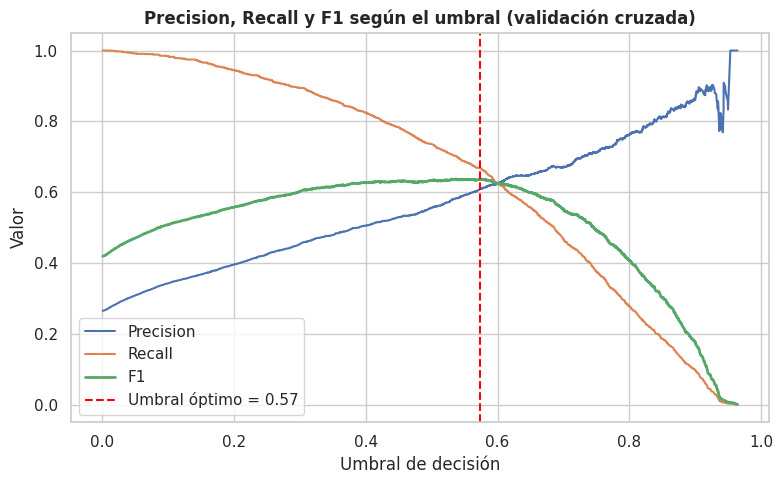

COMPARACIÓN EN EL CONJUNTO DE PRUEBA
           Umbral 0.50  Umbral 0.57
Accuracy        0.7672       0.7793
Precision       0.5439       0.5734
Recall          0.7620       0.6578
F1              0.6347       0.6127
ROC-AUC         0.8440       0.8440

Análisis:
El umbral que maximiza el F1 en validación cruzada es 0.57.
En prueba, el recall pasa de 0.762 a 0.658 y la precision de 0.544 a 0.573.
Bajar el umbral detecta más abandonos a costa de contactar a más clientes que no se iban a ir; la decisión final depende del costo de cada acción de retención.


In [25]:
# 5.3 UMBRAL ÓPTIMO (elegido solo con datos de entrenamiento)
proba_cv = cross_val_predict(modelo_bosque, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, umbrales = precision_recall_curve(y_train, proba_cv)
f1_umbral = 2 * prec * rec / (prec + rec + 1e-12)
umbral_opt = float(umbrales[np.argmax(f1_umbral[:-1])])

plt.figure(figsize=(8, 5))
plt.plot(umbrales, prec[:-1], label='Precision')
plt.plot(umbrales, rec[:-1], label='Recall')
plt.plot(umbrales, f1_umbral[:-1], label='F1', linewidth=2)
plt.axvline(umbral_opt, color='red', linestyle='--', label=f'Umbral óptimo = {umbral_opt:.2f}')
plt.xlabel('Umbral de decisión')
plt.ylabel('Valor')
plt.title('Precision, Recall y F1 según el umbral (validación cruzada)', fontsize=12, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

metr_umbral = calcular_metricas(y_test, proba_bosque, umbral=umbral_opt)
comp = pd.DataFrame({'Umbral 0.50': metr_bosque, f'Umbral {umbral_opt:.2f}': metr_umbral}).round(4)
print('COMPARACIÓN EN EL CONJUNTO DE PRUEBA')
print(comp)

print('\nAnálisis:')
print(f'El umbral que maximiza el F1 en validación cruzada es {umbral_opt:.2f}.')
print(f'En prueba, el recall pasa de {metr_bosque["Recall"]:.3f} a {metr_umbral["Recall"]:.3f} y la precision de {metr_bosque["Precision"]:.3f} a {metr_umbral["Precision"]:.3f}.')
print('Bajar el umbral detecta más abandonos a costa de contactar a más clientes que no se iban a ir; la decisión final depende del costo de cada acción de retención.')

### 5.4 Interpretación: ¿qué variables influyen más?
Se usa la **importancia por permutación** sobre el conjunto de prueba: mide cuánto cae el ROC-AUC cuando se desordenan los valores de una variable. Al aplicarse sobre el pipeline completo, el resultado se expresa en las variables originales (no en columnas one-hot).

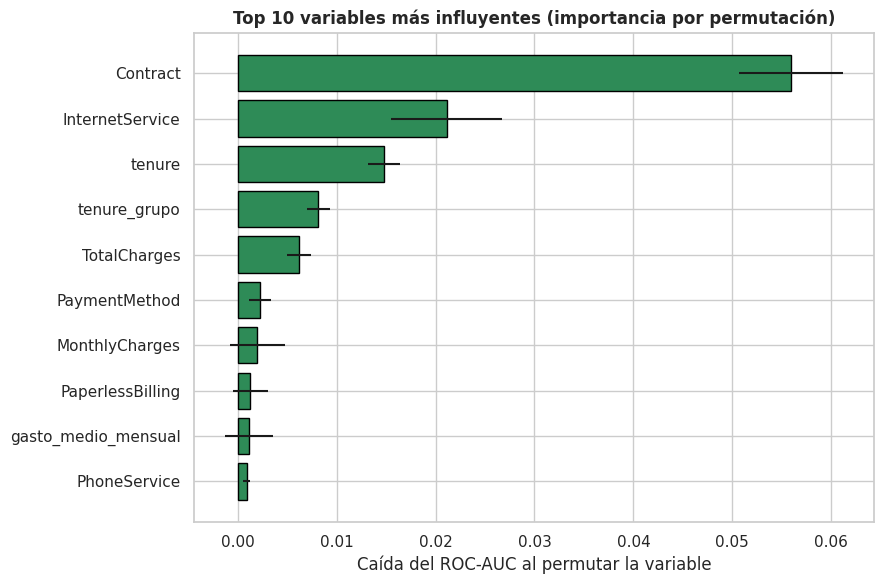

Análisis:
- Contract: caída de ROC-AUC de 0.0559 (± 0.0053).
- InternetService: caída de ROC-AUC de 0.0211 (± 0.0056).
- tenure: caída de ROC-AUC de 0.0148 (± 0.0016).
- tenure_grupo: caída de ROC-AUC de 0.0082 (± 0.0012).
- TotalCharges: caída de ROC-AUC de 0.0062 (± 0.0012).
Estas variables son las que el modelo más necesita para separar a quienes abandonan de quienes se quedan.
Importancia no es causalidad: indica asociación predictiva, no que cambiar la variable evite el abandono.


In [26]:
# 5.4 IMPORTANCIA POR PERMUTACIÓN
perm = permutation_importance(modelo_bosque, X_test, y_test, scoring='roc_auc',
                              n_repeats=10, random_state=SEED, n_jobs=-1)
importancia = pd.DataFrame({'media': perm.importances_mean, 'desv': perm.importances_std},
                           index=X_test.columns).sort_values('media', ascending=False)

top = importancia.head(10).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top['media'], xerr=top['desv'], color='seagreen', edgecolor='black')
plt.xlabel('Caída del ROC-AUC al permutar la variable')
plt.title('Top 10 variables más influyentes (importancia por permutación)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('Análisis:')
for var, fila in importancia.head(5).iterrows():
    print(f'- {var}: caída de ROC-AUC de {fila["media"]:.4f} (± {fila["desv"]:.4f}).')
print('Estas variables son las que el modelo más necesita para separar a quienes abandonan de quienes se quedan.')
print('Importancia no es causalidad: indica asociación predictiva, no que cambiar la variable evite el abandono.')

### 5.5 Valor de negocio: captura de abandonos y lift
Se mide cuántos abandonos se capturan si la empresa contacta solo a los clientes con mayor riesgo.

In [27]:
# 5.5 VALOR DE NEGOCIO: ¿cuántos abandonos se capturan contactando solo a los clientes de mayor riesgo?
orden_riesgo = np.argsort(-proba_bosque)
y_test_arr = y_test.values
total_abandonos = y_test_arr.sum()

filas = []
for frac in [0.10, 0.20, 0.30, 0.40]:
    n_top = int(len(orden_riesgo) * frac)
    capturados = y_test_arr[orden_riesgo[:n_top]].sum()
    filas.append({'% de clientes contactados': frac * 100,
                  'Clientes contactados': n_top,
                  'Abandonos capturados': int(capturados),
                  '% de abandonos capturados': capturados / total_abandonos * 100,
                  'Lift': (capturados / total_abandonos) / frac})
tabla_lift = pd.DataFrame(filas).set_index('% de clientes contactados')
print('CAPTURA DE ABANDONOS SEGÚN EL % DE CLIENTES CONTACTADOS (conjunto de prueba)')
print('=' * 80)
print(tabla_lift)

print('\nAnálisis:')
f20 = tabla_lift.loc[20.0]
print(f'Si la empresa contactara solo al 20% de clientes con mayor riesgo según el modelo, alcanzaría al {f20["% de abandonos capturados"]:.1f}% de los que realmente abandonan (lift de {f20["Lift"]:.2f}).')
print('Un lift mayor que 1 significa que el modelo concentra a los clientes en riesgo mejor que una selección al azar.')

CAPTURA DE ABANDONOS SEGÚN EL % DE CLIENTES CONTACTADOS (conjunto de prueba)
                           Clientes contactados  Abandonos capturados  \
% de clientes contactados                                               
10.0000                                     140                   103   
20.0000                                     281                   189   
30.0000                                     422                   243   
40.0000                                     563                   298   

                           % de abandonos capturados   Lift  
% de clientes contactados                                    
10.0000                                      27.5401 2.7540  
20.0000                                      50.5348 2.5267  
30.0000                                      64.9733 2.1658  
40.0000                                      79.6791 1.9920  

Análisis:
Si la empresa contactara solo al 20% de clientes con mayor riesgo según el modelo, alcanzaría al 50.5

### 5.6 Guardado del modelo final
El archivo incluye el preprocesamiento y el modelo, por lo que sirve directamente sobre datos nuevos con las mismas columnas.

In [28]:
# 5.6 GUARDAR Y VERIFICAR EL MODELO
joblib.dump(modelo_bosque, 'modelo_churn.pkl')
print('Modelo guardado como: modelo_churn.pkl')

# Verificación: cargar y predecir sobre 3 clientes de prueba
modelo_cargado = joblib.load('modelo_churn.pkl')
muestra = X_test.iloc[:3]
probas = modelo_cargado.predict_proba(muestra)[:, 1]
for i, (p, real) in enumerate(zip(probas, y_test.iloc[:3])):
    decision = 'abandona' if p >= umbral_opt else 'se queda'
    print(f'Cliente {i + 1}: probabilidad de abandono = {p:.3f} -> predicción: {decision} (real: {"abandona" if real == 1 else "se queda"})')

# Descarga directa en Colab
try:
    from google.colab import files
    files.download('modelo_churn.pkl')
except Exception:
    pass

Modelo guardado como: modelo_churn.pkl
Cliente 1: probabilidad de abandono = 0.079 -> predicción: se queda (real: se queda)
Cliente 2: probabilidad de abandono = 0.884 -> predicción: abandona (real: se queda)
Cliente 3: probabilidad de abandono = 0.143 -> predicción: se queda (real: se queda)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Resumen y conclusiones

In [29]:
# RESUMEN AUTOMÁTICO DE RESULTADOS
print('RESUMEN DE RESULTADOS')
print('=' * 80)
print(f'1. Datos: {len(df):,} clientes, {df.shape[1]} variables originales; tasa de abandono {tasa_churn:.1f}%.')
print(f'2. Variables categóricas más asociadas con Churn: {", ".join(top3)}.')
print(f'3. Segmentación: K-Means con k = {K_ELEGIDO}; el clúster de mayor riesgo tiene {perfil["tasa_churn"].max():.1f}% de abandono y el de menor {perfil["tasa_churn"].min():.1f}%.')
print(f'4. Mejor modelo en validación cruzada (F1): {mejor_f1}; (ROC-AUC): {mejor_auc}.')
print(f'5. Modelo final (Random Forest ajustado), umbral {umbral_opt:.2f}: '
      f'recall {metr_umbral["Recall"]:.3f}, precision {metr_umbral["Precision"]:.3f}, F1 {metr_umbral["F1"]:.3f}, ROC-AUC {metr_umbral["ROC-AUC"]:.3f}.')
print(f'6. Variables más influyentes: {", ".join(importancia.head(3).index.tolist())}.')
print(f'7. Contactando al 20% de clientes de mayor riesgo se captura el {f20["% de abandonos capturados"]:.1f}% de los abandonos.')

RESUMEN DE RESULTADOS
1. Datos: 7,043 clientes, 21 variables originales; tasa de abandono 26.5%.
2. Variables categóricas más asociadas con Churn: Contract, OnlineSecurity, TechSupport.
3. Segmentación: K-Means con k = 2; el clúster de mayor riesgo tiene 31.4% de abandono y el de menor 18.1%.
4. Mejor modelo en validación cruzada (F1): Random Forest; (ROC-AUC): Random Forest.
5. Modelo final (Random Forest ajustado), umbral 0.57: recall 0.658, precision 0.573, F1 0.613, ROC-AUC 0.844.
6. Variables más influyentes: Contract, InternetService, tenure.
7. Contactando al 20% de clientes de mayor riesgo se captura el 50.5% de los abandonos.


### Conclusiones, limitaciones y trabajo futuro

*(Redacta aquí tus conclusiones con los valores del resumen anterior. Ideas para estructurarlas:)*

- **Respuesta a la pregunta de investigación:** ¿se puede predecir el abandono? ¿con qué calidad (recall, F1, ROC-AUC)?
- **Factores de riesgo:** variables y perfiles de clientes con mayor abandono, y su relación con las acciones de retención.
- **Utilidad del modelo descriptivo:** qué aporta la segmentación frente al modelo predictivo.

**Limitaciones**
- El dataset es una fotografía en un instante: no hay evolución temporal ni se sabe por qué se fue cada cliente.
- Una sola partición entrenamiento/prueba; la estimación puede variar con otra semilla.
- Importancia no equivale a causalidad.
- El umbral óptimo depende de costos de negocio que aquí no se conocen.

**Trabajo futuro:** probar técnicas de remuestreo (SMOTE), otros algoritmos de *boosting* (XGBoost, LightGBM), explicabilidad con SHAP y una estimación del costo-beneficio de las campañas de retención.

### Referencias
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Kaggle. *Telco Customer Churn* (`blastchar/telco-customer-churn`). https://www.kaggle.com/datasets/blastchar/telco-customer-churn

## 7. Despliegue: API y WebApp
Se empaqueta el modelo final en un repositorio con la estructura de entrega: `data/`, `modelo/`, `app/` (API FastAPI + WebApp) y `notebook/`. El código de la API y la WebApp fue **desarrollado con asistencia de IA**. Al final se prueba la API y se descarga el repositorio como `.zip`.

### 7.1 Estructura del repositorio, modelo, umbral y base de datos

In [30]:
# 7.1 REPOSITORIO: carpetas, modelo, umbral y base de datos
import json, shutil, sklearn

REPO = 'churn_repo'
for sub in ['data', 'modelo', 'app', 'notebook', 'docs']:
    os.makedirs(f'{REPO}/{sub}', exist_ok=True)

# Modelo final (pipeline completo) y umbral de decisión
joblib.dump(modelo_bosque, f'{REPO}/modelo/modelo_churn.pkl')
with open(f'{REPO}/modelo/umbral.json', 'w') as f:
    json.dump({'umbral': float(umbral_opt)}, f)

# Base de datos original
df.to_csv(f'{REPO}/data/WA_Fn-UseC_-Telco-Customer-Churn.csv', index=False)

# requirements.txt con la versión exacta de scikit-learn usada en el entrenamiento
with open(f'{REPO}/app/requirements.txt', 'w') as f:
    f.write(f'fastapi\nuvicorn\npandas\nnumpy\njoblib\nscikit-learn=={sklearn.__version__}\n')

print('Modelo guardado en', f'{REPO}/modelo/modelo_churn.pkl')
print(f'Umbral guardado: {umbral_opt:.4f} | scikit-learn {sklearn.__version__}')

Modelo guardado en churn_repo/modelo/modelo_churn.pkl
Umbral guardado: 0.5735 | scikit-learn 1.6.1


### 7.2 Código fuente de la API (FastAPI)
Expone `POST /predict` y `GET /health`; repite el *feature engineering* de la Fase 3.2 sobre el cliente recibido.

In [31]:
%%writefile churn_repo/app/app.py
"""API de predicción de abandono (Telco Churn) + WebApp.

Ejecutar desde la carpeta app/:  uvicorn app:app --reload
Web:       http://127.0.0.1:8000/
Swagger:   http://127.0.0.1:8000/docs
"""
import json
from pathlib import Path
from typing import Literal, Optional

import joblib
import numpy as np
import pandas as pd
from fastapi import FastAPI
from fastapi.responses import FileResponse
from pydantic import BaseModel, Field

BASE = Path(__file__).parent
MODELO_DIR = BASE.parent / "modelo"  # carpeta del repositorio con modelo_churn.pkl y umbral.json
if not MODELO_DIR.exists():
    MODELO_DIR = BASE
modelo = joblib.load(MODELO_DIR / "modelo_churn.pkl")  # pipeline completo (prep + Random Forest)

# El umbral óptimo se guarda desde el notebook (umbral.json). Si no existe, se usa 0.5.
try:
    UMBRAL = float(json.loads((MODELO_DIR / "umbral.json").read_text())["umbral"])
except Exception:
    UMBRAL = 0.5

SiNo = Literal["Yes", "No"]

app = FastAPI(title="API Telco Churn", version="1.0",
              description="Predice la probabilidad de abandono de un cliente de telecomunicaciones.")


class Cliente(BaseModel):
    gender: Literal["Female", "Male"] = "Female"
    SeniorCitizen: SiNo = "No"
    Partner: SiNo = "No"
    Dependents: SiNo = "No"
    tenure: int = Field(3, ge=0, le=72, description="Meses de antigüedad")
    PhoneService: SiNo = "Yes"
    MultipleLines: SiNo = "No"
    InternetService: Literal["DSL", "Fiber optic", "No"] = "Fiber optic"
    OnlineSecurity: SiNo = "No"
    OnlineBackup: SiNo = "No"
    DeviceProtection: SiNo = "No"
    TechSupport: SiNo = "No"
    StreamingTV: SiNo = "No"
    StreamingMovies: SiNo = "No"
    Contract: Literal["Month-to-month", "One year", "Two year"] = "Month-to-month"
    PaperlessBilling: SiNo = "Yes"
    PaymentMethod: Literal["Electronic check", "Mailed check",
                           "Bank transfer (automatic)", "Credit card (automatic)"] = "Electronic check"
    MonthlyCharges: float = Field(75.0, ge=0)
    TotalCharges: Optional[float] = Field(None, ge=0, description="Si se omite: tenure x MonthlyCharges")


def preparar(c: Cliente) -> pd.DataFrame:
    """Repite el feature engineering del notebook (Fase 3.2) sobre un cliente nuevo."""
    d = c.model_dump()
    if d["TotalCharges"] is None:
        d["TotalCharges"] = d["tenure"] * d["MonthlyCharges"]
    df = pd.DataFrame([d])

    servicios = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                 "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
    df["n_servicios"] = (df[servicios] == "Yes").sum(axis=1) + (df["InternetService"] != "No").astype(int)
    df["gasto_medio_mensual"] = df["TotalCharges"] / df["tenure"].clip(lower=1)
    df["variacion_cargo"] = df["MonthlyCharges"] - df["gasto_medio_mensual"]
    df["tenure_grupo"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                                labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)
    prot = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
    df["tiene_proteccion"] = np.where((df[prot] == "Yes").any(axis=1), "Yes", "No")
    return df


@app.get("/health")
def health():
    return {"estado": "ok", "umbral": UMBRAL}


@app.post("/predict")
def predict(cliente: Cliente):
    proba = float(modelo.predict_proba(preparar(cliente))[0, 1])
    if proba >= UMBRAL:
        nivel = "Alto"
    elif proba >= UMBRAL / 2:
        nivel = "Medio"
    else:
        nivel = "Bajo"
    return {"probabilidad_abandono": round(proba, 4),
            "umbral": round(UMBRAL, 4),
            "prediccion": "Abandona" if proba >= UMBRAL else "Se queda",
            "nivel_riesgo": nivel}


@app.get("/", include_in_schema=False)
def web():
    return FileResponse(BASE / "index.html")

Writing churn_repo/app/app.py


### 7.3 Código fuente de la WebApp
Formulario HTML que consume la API y muestra la probabilidad de abandono y el nivel de riesgo.

In [32]:
%%writefile churn_repo/app/index.html
<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Predicción de abandono de clientes</title>
<style>
  body{font-family:Arial,sans-serif;background:#f3f5f9;margin:0;color:#222}
  header{background:#1f3a5f;color:#fff;padding:18px 24px}
  header h1{margin:0;font-size:20px} header p{margin:4px 0 0;font-size:13px;opacity:.85}
  main{max-width:900px;margin:20px auto;padding:0 16px;display:grid;gap:16px;grid-template-columns:1fr 1fr}
  @media(max-width:700px){main{grid-template-columns:1fr}}
  .card{background:#fff;border-radius:8px;padding:18px;box-shadow:0 1px 4px #0002}
  label{display:block;font-size:12px;margin:8px 0 2px;color:#555}
  select,input{width:100%;padding:6px;border:1px solid #bbb;border-radius:4px;box-sizing:border-box}
  button{margin-top:14px;width:100%;padding:10px;background:#1f3a5f;color:#fff;border:0;border-radius:4px;font-size:15px;cursor:pointer}
  #res{text-align:center}
  .barra{height:18px;background:#ddd;border-radius:9px;overflow:hidden;margin:10px 0}
  #fill{height:100%;width:0;background:#2e9e5b;transition:width .4s}
  #pct{font-size:42px;font-weight:bold;margin:6px 0}
  .tag{display:inline-block;padding:4px 14px;border-radius:14px;color:#fff;font-weight:bold}
</style>
</head>
<body>
<header><h1>Predicción de abandono de clientes (Telco Churn)</h1>
<p>Minería de Datos · Random Forest · API FastAPI</p></header>
<main>
<div class="card">
  <h3>Datos del cliente</h3>
  <div id="campos"></div>
  <button onclick="predecir()">Predecir</button>
</div>
<div class="card" id="res">
  <h3>Resultado</h3>
  <p id="msg">Completa el formulario y pulsa «Predecir».</p>
  <div id="pct"></div>
  <div class="barra"><div id="fill"></div></div>
  <span id="nivel" class="tag" style="display:none"></span>
  <p id="pred"></p>
</div>
</main>
<script>
const SN=["No","Yes"];
const CAMPOS=[
 ["gender","Género",["Female","Male"]],["SeniorCitizen","Adulto mayor",SN],["Partner","Pareja",SN],["Dependents","Dependientes",SN],
 ["tenure","Antigüedad (meses, 0-72)","num",3],["PhoneService","Servicio telefónico",["Yes","No"]],["MultipleLines","Múltiples líneas",SN],
 ["InternetService","Internet",["Fiber optic","DSL","No"]],["OnlineSecurity","Seguridad online",SN],["OnlineBackup","Respaldo online",SN],
 ["DeviceProtection","Protección de equipo",SN],["TechSupport","Soporte técnico",SN],["StreamingTV","Streaming TV",SN],["StreamingMovies","Streaming películas",SN],
 ["Contract","Contrato",["Month-to-month","One year","Two year"]],["PaperlessBilling","Factura electrónica",["Yes","No"]],
 ["PaymentMethod","Método de pago",["Electronic check","Mailed check","Bank transfer (automatic)","Credit card (automatic)"]],
 ["MonthlyCharges","Cargo mensual (USD)","num",75]
];
const cont=document.getElementById("campos");
CAMPOS.forEach(([id,txt,op,def])=>{
  const l=document.createElement("label");l.textContent=txt;l.htmlFor=id;cont.appendChild(l);
  let e;
  if(op==="num"){e=document.createElement("input");e.type="number";e.step="any";e.min=0;e.value=def}
  else{e=document.createElement("select");op.forEach(o=>e.add(new Option(o,o)))}
  e.id=id;cont.appendChild(e);
});
async function predecir(){
  const body={};
  CAMPOS.forEach(([id,,op])=>{const v=document.getElementById(id).value;body[id]=op==="num"?parseFloat(v):v});
  const msg=document.getElementById("msg");
  try{
    const r=await fetch("/predict",{method:"POST",headers:{"Content-Type":"application/json"},body:JSON.stringify(body)});
    if(!r.ok)throw new Error("Error "+r.status);
    const d=await r.json();
    const p=d.probabilidad_abandono*100;
    const col={Alto:"#d64545",Medio:"#e0a020",Bajo:"#2e9e5b"}[d.nivel_riesgo];
    msg.textContent="";
    document.getElementById("pct").textContent=p.toFixed(1)+"%";
    const f=document.getElementById("fill");f.style.width=p+"%";f.style.background=col;
    const n=document.getElementById("nivel");n.style.display="inline-block";n.style.background=col;n.textContent="Riesgo "+d.nivel_riesgo;
    document.getElementById("pred").textContent="Predicción: "+d.prediccion+" (umbral "+d.umbral.toFixed(2)+")";
  }catch(e){msg.textContent="No se pudo consultar la API: "+e.message}
}
</script>
</body>
</html>

Writing churn_repo/app/index.html


### 7.4 README y .gitignore del repositorio

In [33]:
README = r'''# Predicción del abandono de clientes (Telco Churn)

Práctica experimental 1 · Minería de Datos · Universidad Estatal Amazónica
Autor: Jordy Josué Parión Aigaje

Aplicación del proceso de minería de datos al conjunto *Telco Customer Churn* (Kaggle): exploración,
preprocesamiento, segmentación con K-Means, comparación de modelos de clasificación, ajuste de un
Random Forest, API y WebApp.

## Estructura

| Carpeta | Contenido |
|---|---|
| `notebook/` | Cuaderno `Telco_Churn_Mineria_Datos.ipynb` (Google Colab) |
| `data/` | Base de datos `WA_Fn-UseC_-Telco-Customer-Churn.csv` ([Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)) |
| `modelo/` | `modelo_churn.pkl` (pipeline: preprocesamiento + Random Forest) y `umbral.json` |
| `app/` | Código fuente de la API (FastAPI, `app.py`) y de la WebApp (`index.html`). Desarrollados con asistencia de IA |
| `docs/` | Informe y cuaderno en PDF |

## Ejecutar la API y la WebApp

```bash
cd app
python -m venv .venv && source .venv/bin/activate   # Windows: .venv\Scripts\activate
pip install -r requirements.txt
uvicorn app:app --reload
```

- WebApp: http://127.0.0.1:8000/
- Documentación de la API (Swagger): http://127.0.0.1:8000/docs
- Endpoints: `GET /health`, `POST /predict`

Ejemplo:

```bash
curl -X POST http://127.0.0.1:8000/predict -H "Content-Type: application/json" \
  -d '{"tenure":3,"Contract":"Month-to-month","InternetService":"Fiber optic","MonthlyCharges":85}'
```

## Nota
El modelo se entrenó con la versión de scikit-learn indicada en `app/requirements.txt`; usa esa misma versión.
'''
GITIGNORE = '''__pycache__/
*.pyc
.venv/
.ipynb_checkpoints/
.DS_Store
'''
open('churn_repo/README.md', 'w', encoding='utf-8').write(README)
open('churn_repo/.gitignore', 'w').write(GITIGNORE)
print('README.md y .gitignore creados.')

README.md y .gitignore creados.


### 7.5 Prueba de la API
Se prueban dos clientes de perfil opuesto con el cliente de pruebas de FastAPI (sin levantar un servidor). Esta salida sirve de evidencia del funcionamiento de la API.

In [34]:
# 7.5 PRUEBA DE LA API
!pip install -q fastapi httpx
import sys, importlib
sys.path.insert(0, 'churn_repo/app')
import app as api_app
importlib.reload(api_app)
from fastapi.testclient import TestClient

cliente_api = TestClient(api_app.app)
print('GET /health ->', cliente_api.get('/health').json())

riesgo_alto = {'tenure': 2, 'Contract': 'Month-to-month', 'InternetService': 'Fiber optic',
               'PaymentMethod': 'Electronic check', 'MonthlyCharges': 90.0}
riesgo_bajo = {'tenure': 60, 'Contract': 'Two year', 'InternetService': 'DSL',
               'PaymentMethod': 'Credit card (automatic)', 'MonthlyCharges': 55.0,
               'OnlineSecurity': 'Yes', 'TechSupport': 'Yes', 'Partner': 'Yes', 'Dependents': 'Yes'}

for nombre, datos in [('Cliente de riesgo alto', riesgo_alto), ('Cliente de riesgo bajo', riesgo_bajo)]:
    r = cliente_api.post('/predict', json=datos)
    print(f'POST /predict - {nombre}: HTTP {r.status_code} ->', r.json())

print('\nAnálisis:')
print('La API recibe los datos crudos de un cliente, reconstruye las variables derivadas y devuelve la probabilidad de abandono, la decisión según el umbral y un nivel de riesgo.')

GET /health -> {'estado': 'ok', 'umbral': 0.5735127470759912}
POST /predict - Cliente de riesgo alto: HTTP 200 -> {'probabilidad_abandono': 0.8812, 'umbral': 0.5735, 'prediccion': 'Abandona', 'nivel_riesgo': 'Alto'}
POST /predict - Cliente de riesgo bajo: HTTP 200 -> {'probabilidad_abandono': 0.0398, 'umbral': 0.5735, 'prediccion': 'Se queda', 'nivel_riesgo': 'Bajo'}

Análisis:
La API recibe los datos crudos de un cliente, reconstruye las variables derivadas y devuelve la probabilidad de abandono, la decisión según el umbral y un nivel de riesgo.


### 7.6 Descarga del repositorio
Se comprime la carpeta `churn_repo`. Después de descargarla, copia dentro de `notebook/` este cuaderno ejecutado y dentro de `docs/` los PDF del informe y del cuaderno, y súbelo a GitHub.

In [36]:
# 7.6 EMPAQUETAR EL REPOSITORIO
shutil.make_archive('churn_repo', 'zip', '.', 'churn_repo')
print('Creado churn_repo.zip')
try:
    from google.colab import files
    files.download('churn_repo.zip')
except Exception:
    pass

Creado churn_repo.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>